## Reinforcement Learning Project


### Cab-Driver Agent


In [1]:
# Importing libraries
import numpy as np
import random
import math
from collections import deque
import collections
import pickle
from datetime import datetime
import time

# for building DQN model
from keras import layers
from keras import Sequential
from keras.layers import Dense, Activation, Flatten, Dropout
import tensorflow as tf
from tensorflow.keras.optimizers import Adam

# for plotting graphs
import matplotlib.pyplot as plt

# Import the environment
import Env
from Env import CabDriver

#### Defining Time Matrix


In [2]:
# Loading the time matrix provided
Time_matrix = np.load("TM.npy")

## Tracking the state-action pairs for checking convergence

- Initializing with a few random states with their possible action spaces
- During training, we will keep accumulating their evolving Q-values to check convergence


In [3]:
NUMBER_OF_STATES_TO_TRACK = 15
States_track = collections.defaultdict(dict)

# Initialise states to be tracked
def initialise_tracking_states():
    sample_q_values = []
   
    for i in range(NUMBER_OF_STATES_TO_TRACK):
        cb = CabDriver()
        action_space,state_space,state = cb.reset()
        for a in range(0,len(action_space)):
            sample_q_values.append((state,a))
    # print("sample_q_values",sample_q_values)
    for q_values in sample_q_values:
        state = q_values[0]
        action = q_values[1]
        States_track[state][action] = [] 

In [4]:
print(len(States_track))

0


In [5]:
# test
# initialise_tracking_states()
# print(len(States_track))

In [6]:
cb_temp = CabDriver()
def save_tracking_states(model):
    for state in States_track.keys():
        encoded_state = cb_temp.state_encod_arch1(state)
        encoded_state = encoded_state.reshape(1, len(encoded_state))
        # predict the q_vals and store them
        action_probabilities = model.predict(encoded_state)
        for i,a in enumerate(action_probabilities[0]):
            # print(f"action:{i}, q_val:{a}")
            States_track[state][i].append(a)

In [7]:
#Defining a function to save the Q-dictionary as a pickle file
def save_obj(obj, name ):
    with open(name + '.pkl', 'wb') as f:
        pickle.dump(obj, f, pickle.HIGHEST_PROTOCOL)

### Agent Class

1. State and Action Size
2. Hyperparameters
3. 'build_model()' function to make an NN model
4. Define epsilon-greedy strategy in function 'get_action()'
5. Memory collector:'append_sample()'. This function appends the recent experience tuple <state, action, reward, new-state> to the memory
6. 'train_model()' function with following logic:
   - If the memory size is greater than mini-batch size, you randomly sample experiences from memory as per the mini-batch size and do the following:
     - Initialise input and output batch for training the model
     - Calculate the target Q value for each sample: reward + gamma\*max(Q(s'a,))
     - Get Q(s', a) values from the last trained model
     - Update the input batch as your encoded state and output batch as the Q-values
     - Then fit DQN model using the updated input and output batch.


In [8]:
class DQNAgent:
    def __init__(self, state_size, action_size):
        # Define size of state and action
        self.state_size = state_size
        self.action_size = action_size

        # hyper parameters for the DQN
        self.discount_factor = 0.80
        self.learning_rate =  0.005
        self.enable_dropout = False
        self.dropout_factor = 0.25     
        
        self.epsilon_max = 1.0
        self.epsilon_min = 0
        self.epsilon = self.epsilon_max
        self.epsilon_decay = -0.002
        self.epsilon_decay2 = 0.99
        
        
        self.batch_size = 32        
        # create replay memory using deque
        self.memory = deque(maxlen=2000)

        # create main model and target model
        self.model = self.build_model()

    # approximate Q function using Neural Network
    def build_model(self):
        model = Sequential()
        # Write your code here: Add layers to your neural nets       
        model.add(Dense(64, input_dim=self.state_size, activation='relu', kernel_initializer='he_uniform'))
        if self.enable_dropout:
          model.add(Dropout(self.dropout_factor))
        model.add(Dense(64, activation='relu', kernel_initializer='he_uniform'))

        model.add(Dense(self.action_size, activation='relu', kernel_initializer='he_uniform'))
        model.compile(loss='mse', 
                      optimizer=Adam(learning_rate=self.learning_rate),
                      metrics=['accuracy', 'mse'])
        model.summary()
        return model

    def get_action_index(self, state, possible_action_indeces):
    
        z = np.random.random()
     
        # if we happen to land on a value greater than decay curve point, we exploit
        if z > self.epsilon:
            action_probabilities = self.model.predict(state)
            return np.argmax(action_probabilities)
        else:   
            return random.choice(possible_action_indeces)
        

    def append_sample(self, state, action, reward, next_state, done):
        """appends the new agent run output to replay buffer"""
        self.memory.append((state, action, reward, next_state, done))
    
    
    
    # pick samples randomly from replay memory (with batch_size) and train the network
    def train_model(self):
        
        if len(self.memory) > self.batch_size:
            # Sample batch from the memory
            mini_batch = random.sample(self.memory, self.batch_size)
            
            update_output = np.zeros((self.batch_size, self.state_size))
            update_input = np.zeros((self.batch_size, self.state_size))
            
            actions, rewards, terminal_states = [], [], []
            
            for i in range(self.batch_size):
                state, action, reward, next_state, done = mini_batch[i]
                
                update_input[i] = state
                actions.append(action)
                rewards.append(reward)
                terminal_states.append(done)
                
                update_output[i] = next_state
                
            # Write your code from here
            # 1. Predict the target from earlier model
            target = self.model.predict(update_input)

            # 2. Get the target for the Q-network
            target_qval = self.model.predict(update_output)
                
            #3. Update your 'update_output' and 'update_input' batch
            for i in range(self.batch_size):
                if terminal_states[i]:
                    target[i][actions[i]] = rewards[i]
                else: # non-terminal state
                    target[i][actions[i]] = rewards[i] + self.discount_factor * np.max(target_qval[i])
                
            # 4. Fit your model and track the loss values
            model_stats = self.model.fit(update_input, target, batch_size=self.batch_size, epochs=1, verbose=0)
            return model_stats
        else:
            return None
    
    def save(self, name):
        with open(name + '.pkl', 'wb') as file:
            pickle.dump(self.model, file, pickle.HIGHEST_PROTOCOL)
        #self.model.save(filepath='./'+name + '.pkl')
    
    def decay(self, time):
        #self.epsilon = (self.epsilon_max - self.epsilon_min) * np.exp(agent.epsilon_decay * time)
        self.epsilon = self.epsilon*self.epsilon_decay2

### DQN block


In [9]:
EPISODES = 1000

# state tracking will kickstart after these many episodes. Lets keep it proportial to the number of episodes
START_TRACKING_EVERY = int(EPISODES*0.01)

# track progress after every % of episodes covered
EPISODES_PROGRESS_INDICATOR = int(EPISODES*0.01)

#30 days before which car has to be recharged
EPISODE_TIME_HOURS = 24*30

# lets have a progress printed roughly every week
EPISODE_PROGRESS_INDICATOR_HOURS = EPISODE_TIME_HOURS//4

In [10]:
print(f"Total Episodes: {EPISODES}")
print(f"States will be tracked after every [{START_TRACKING_EVERY}] Episodes")
print(f"Progress will be updated after very [{EPISODES_PROGRESS_INDICATOR}] Episodes")

Total Episodes: 1000
States will be tracked after every [10] Episodes
Progress will be updated after very [10] Episodes


In [11]:
reward_tracker = []
episode_time_tracker = []
trips_per_episode_tracker = []
inactivity_tracker = []
model_accuracy_tracker = []
model_loss_tracker = []

episodes_start_time = datetime.now()

cab_driver = CabDriver()
action_space,state_space,state = cab_driver.reset()
action_size = len(action_space)
state_size = len(cab_driver.state_encod_arch1(state))

print(f"action_size: {action_size}, state_size:{state_size}")

# define DQN Agent once for all the episodes
agent = DQNAgent(state_size, action_size)
    
#episode_time = 1
for episode in range(EPISODES):
    episode_start_time = datetime.now()
    #print("="*50)
    #print(f"Episode {episode} start at {episode_start_time}")
    cab_driver = CabDriver()
    action_space,state_space,state = cab_driver.reset()

    # we begin the journey fresh
    terminal_state = False
    total_trips_time = 0
    reward_per_episode = 0
    last_recorded_day = 0
    trips_per_episode = 0
    inactivity = 0
    while terminal_state == False:
        # Write your code here
        # 1. Pick epsilon-greedy action from possible actions for the current state
         
        # get the possible actions the driver can take
        possible_actions_indeces, possible_actions = cab_driver.requests(state)
        # encode the state to make it feedable into neural network
        encoded_state = cab_driver.state_encod_arch1(state)
        encoded_state = encoded_state.reshape(1, len(encoded_state))
        # get the epsilon greedy action
        action_index = agent.get_action_index(encoded_state, possible_actions_indeces)

        # 2. Evaluate your reward and next state
        reward = cab_driver.reward_func(state, action_space[action_index], Time_matrix)
        next_state, time_of_trip = cab_driver.next_state_func(state, action_space[action_index],Time_matrix)

        # if cab driver opted for action (0,0), lets track that
        if state[0] == next_state[0]:
          inactivity += 1
    
        # accumulate time
        total_trips_time += time_of_trip

        # accumulate trips done
        trips_per_episode += 1
        
        if total_trips_time >= EPISODE_TIME_HOURS:
            terminal_state = True
        
        # 3. Append the experience to the memory
        agent.append_sample(cab_driver.state_encod_arch1(state), action_index, reward, cab_driver.state_encod_arch1(next_state), terminal_state)
        
        # 4. Train the model by calling function agent.train_model
        model_stats = agent.train_model()
        
        # 5. Keep a track of rewards, Q-values, loss
        reward_per_episode += reward
        # update the state to next state
        state = next_state
        # lets track accuracy and loss at the end of each episode
        if terminal_state and model_stats != None:
            model_accuracy_tracker.append(model_stats.history['accuracy'])
            model_loss_tracker.append(model_stats.history['mse'])
    
    reward_tracker.append(reward_per_episode)
    episode_time_tracker.append(total_trips_time)
    trips_per_episode_tracker.append(trips_per_episode)
    inactivity_tracker.append(inactivity)
    
    if episode + 1 == START_TRACKING_EVERY:
        initialise_tracking_states()
    
    # after reaching the tracking schedule iota of journey, saves the metrics
    if (episode + 1) % START_TRACKING_EVERY == 0:
        save_tracking_states(agent.model)
        save_obj(States_track,'States_tracked')
        save_obj(reward_tracker,'Rewards_tracked')
        save_obj(model_loss_tracker,'Model_loss_tracked')
        save_obj(episode_time_tracker,'Episode_time_tracked')
        save_obj(trips_per_episode_tracker,'Trips_per_episode_tracked')
        save_obj(inactivity_tracker,'Inactivity_per_episode_tracked')
    
    if (episode + 1) % EPISODES_PROGRESS_INDICATOR == 0:
        print("="*50)
        print(f"Progress: {round(((episode + 1)*100/EPISODES),2)}%")
        print(f"Episode: {episode + 1}")
        print(f"Reward: {reward_per_episode}")
        print(f"Model Accuracy: {model_accuracy_tracker[-1]}")
        print(f"Model Loss: {model_loss_tracker[-1]}")
        print(f"Episode Time: {total_trips_time}")
        print(f"Episode Trips done: {trips_per_episode}")
        print(f"Inactivity count: {inactivity}")
        print(f"Agent's epsilon: {agent.epsilon}")
        current_time = datetime.now()
        time_diff = current_time.timestamp() - episodes_start_time.timestamp()
        t = math.ceil(time_diff)//60
        print(f"Elapsed time: {t} minutes")
        print(f"Saving Model after Episode {episode + 1}")
        agent.save("DQN_model")
        print("="*50)
      
    # epsilon decay
    agent.decay(episode)

current_time = datetime.now()
time_diff = current_time.timestamp() - episodes_start_time.timestamp()
total_time = math.ceil(time_diff)//60
print(f"Total time taken: {total_time} minutes")
# save the model for the last time
agent.save("DQN_model")

action_size: 21, state_size:36
Model: "sequential"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 dense (Dense)               (None, 64)                2368      
                                                                 
 dense_1 (Dense)             (None, 64)                4160      
                                                                 
 dense_2 (Dense)             (None, 21)                1365      
                                                                 
Total params: 7,893
Trainable params: 7,893
Non-trainable params: 0
_________________________________________________________________
Progress: 1.0%
Episode: 10
Reward: -25.0
Model Accuracy: [0.90625]
Model Loss: [86.61196899414062]
Episode Time: 725.0
Episode Trips done: 116
Inactivity count: 17
Agent's epsilon: 0.9135172474836407
Elapsed time: 2 minutes
Saving Model after Episode 10
INFO:tensorflow:Assets written to

### Tracking Convergence


In [12]:
# Write the code for plotting the graphs for state-action pairs tracked
# function to show state-action value plot
import seaborn as sns
import matplotlib.pyplot as plt

def show_plot(time_series, title):
    plt.title(title)
    plt.plot(time_series)
    plt.show()

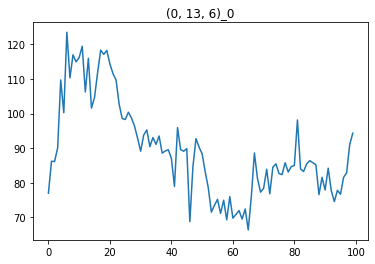

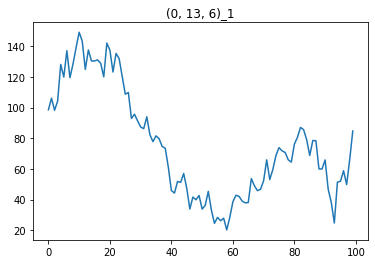

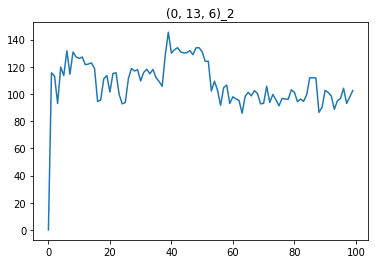

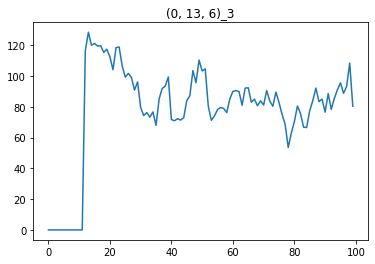

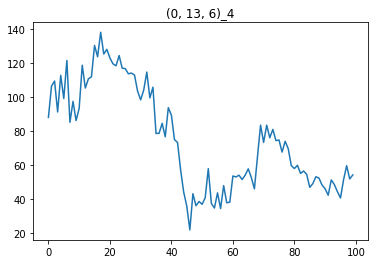

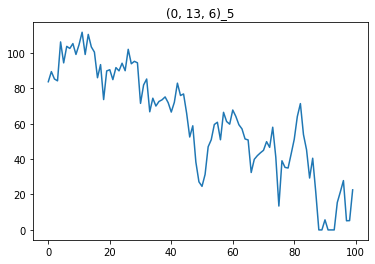

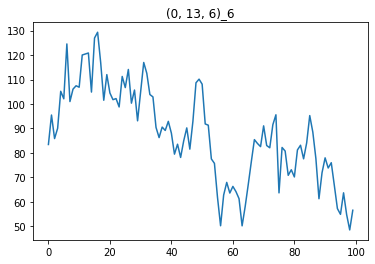

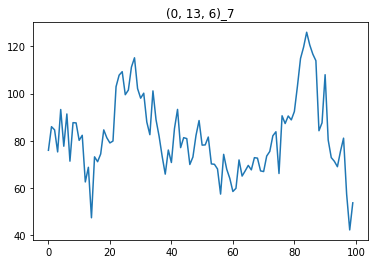

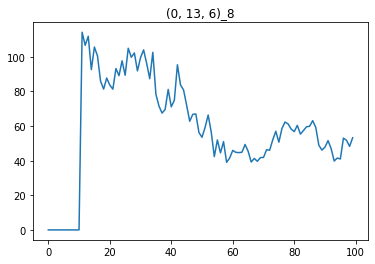

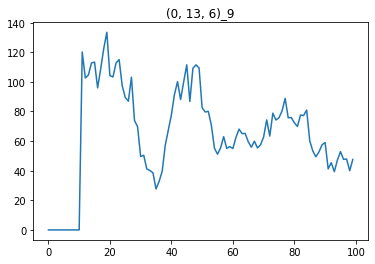

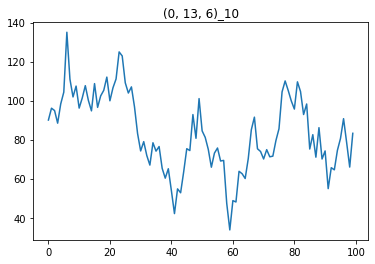

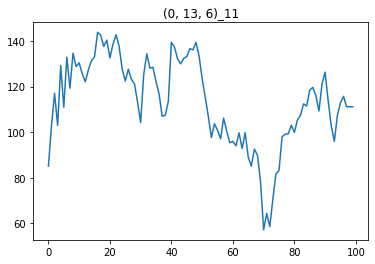

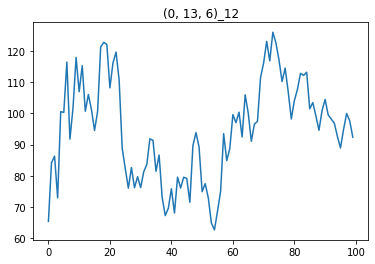

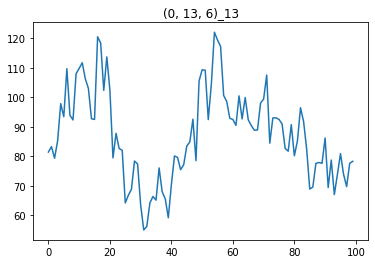

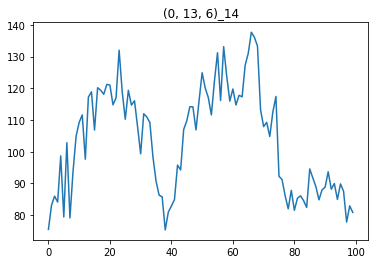

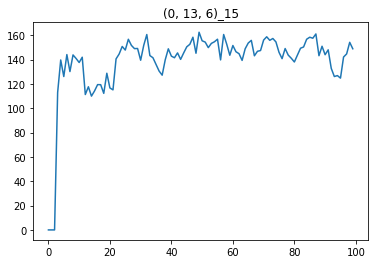

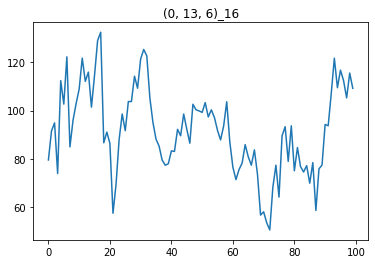

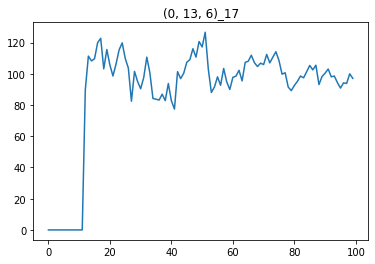

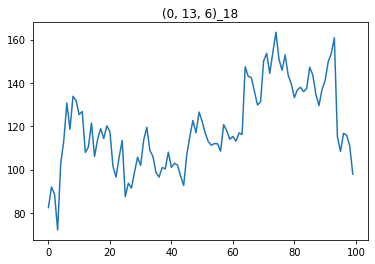

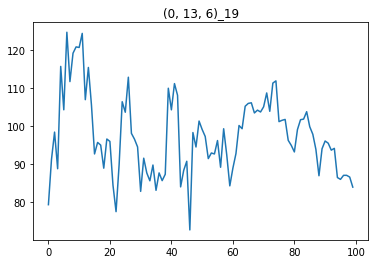

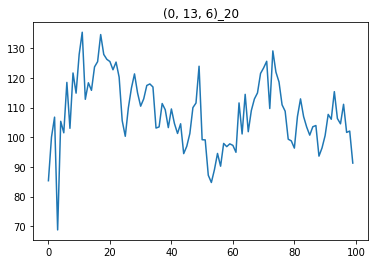

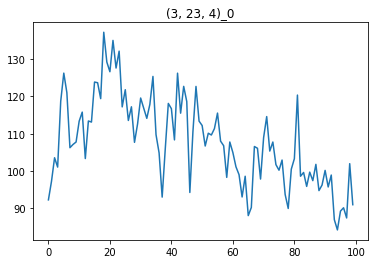

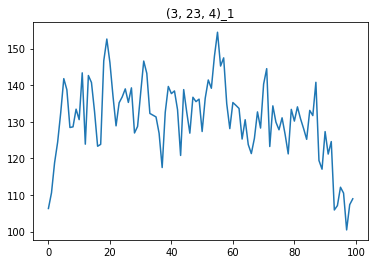

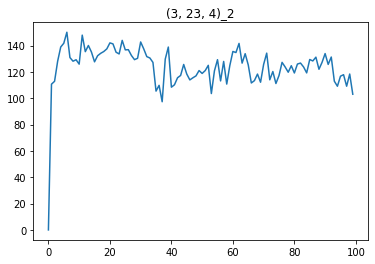

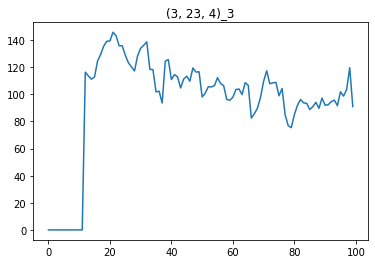

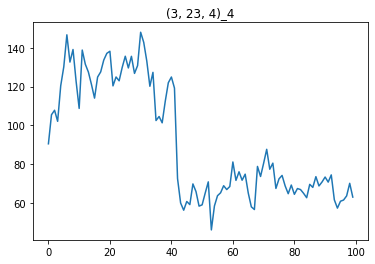

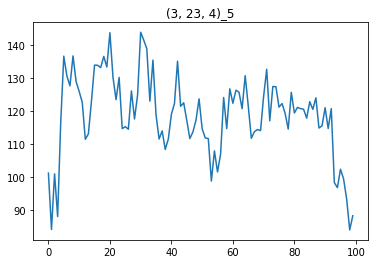

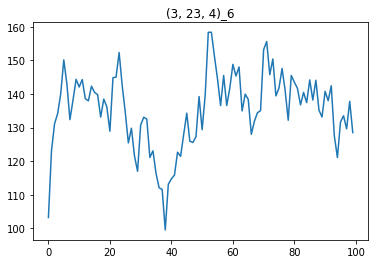

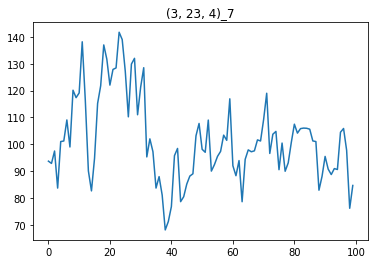

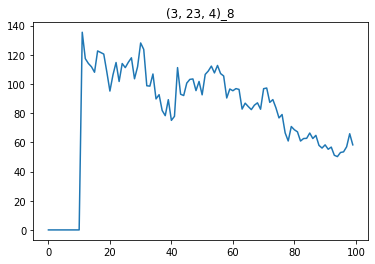

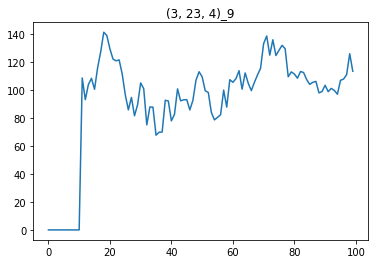

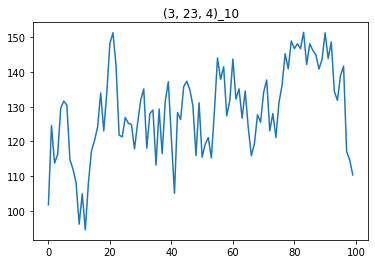

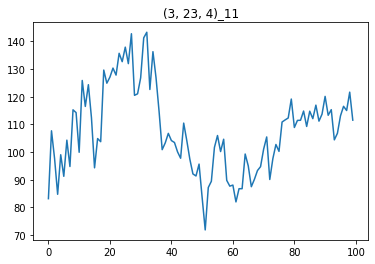

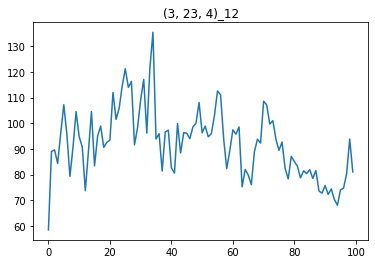

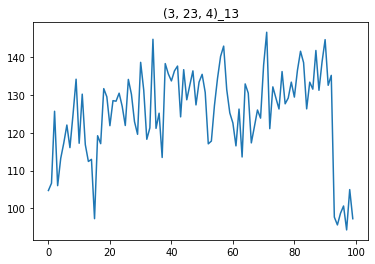

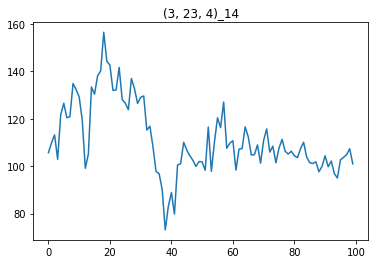

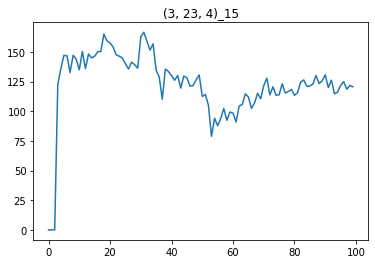

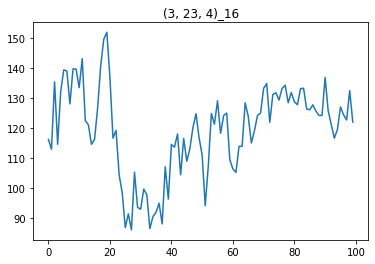

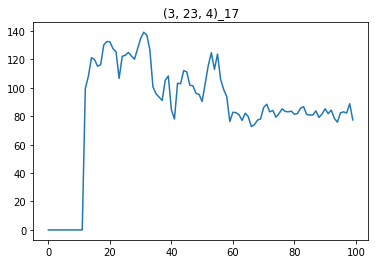

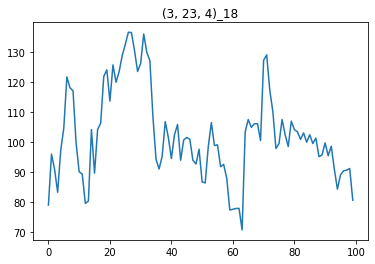

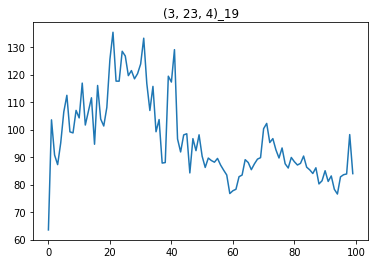

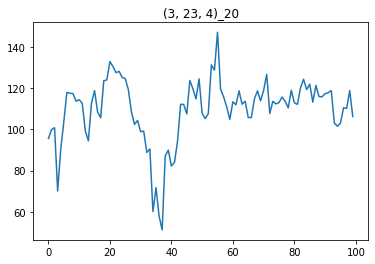

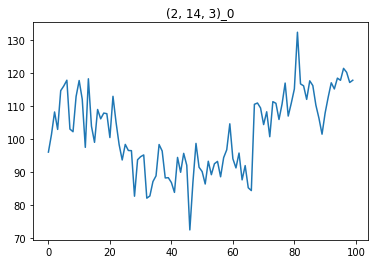

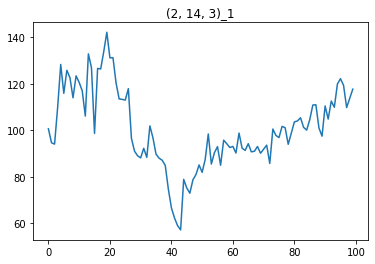

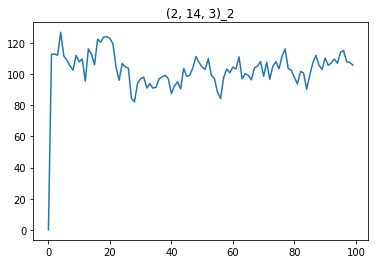

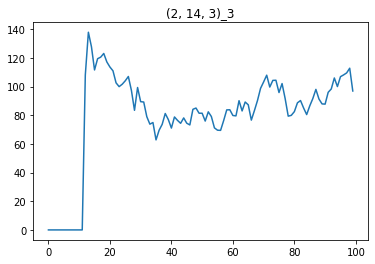

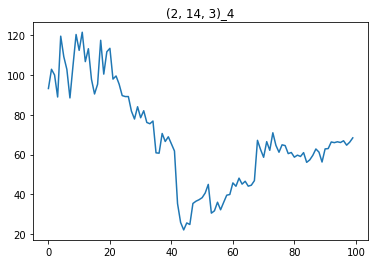

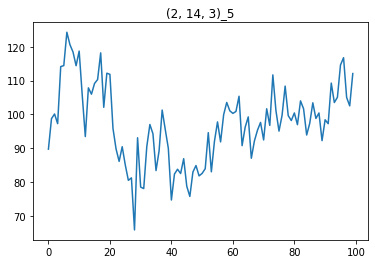

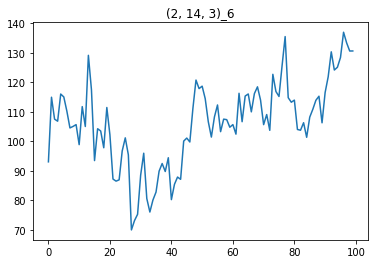

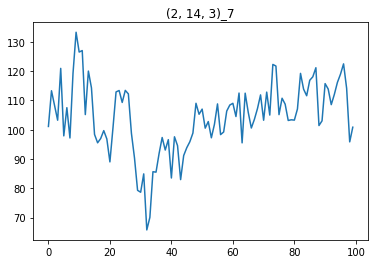

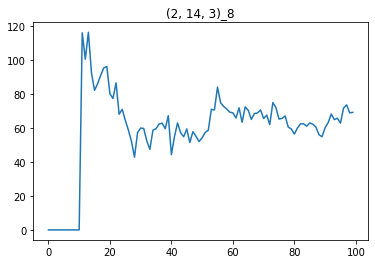

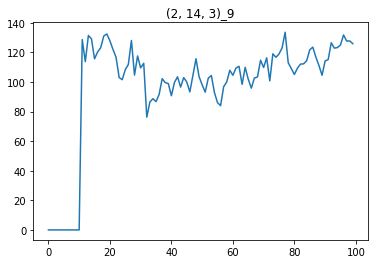

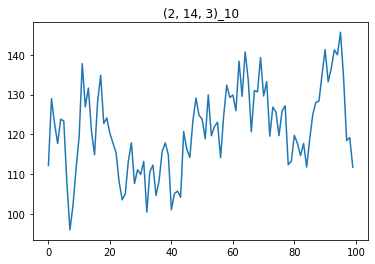

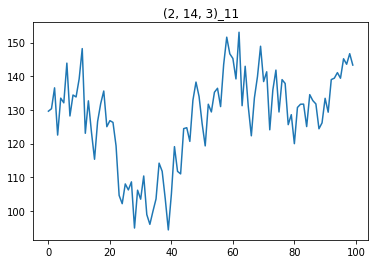

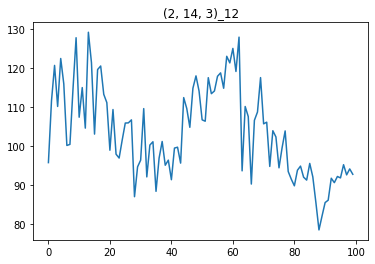

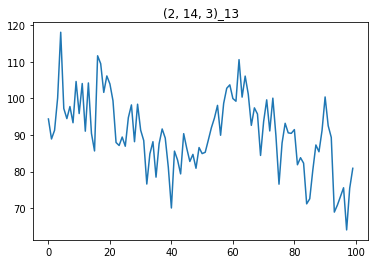

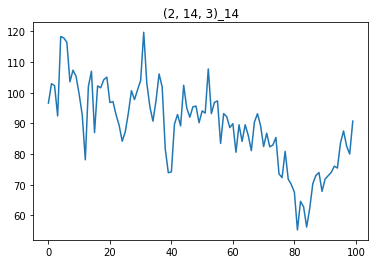

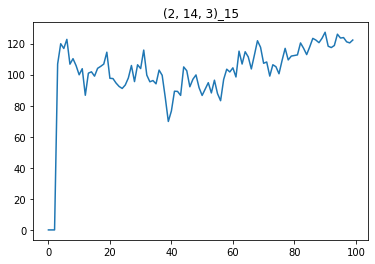

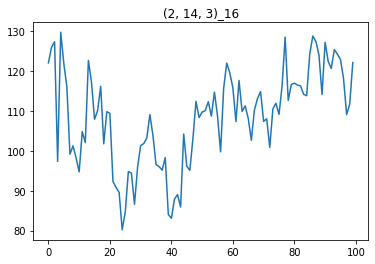

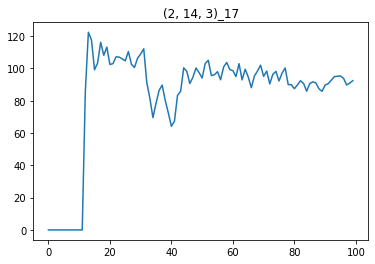

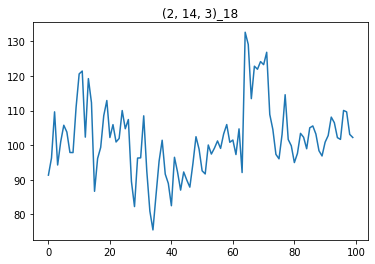

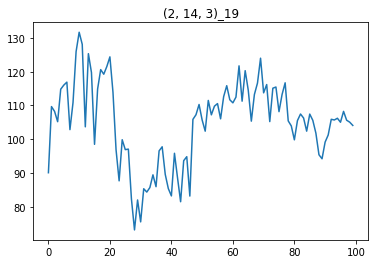

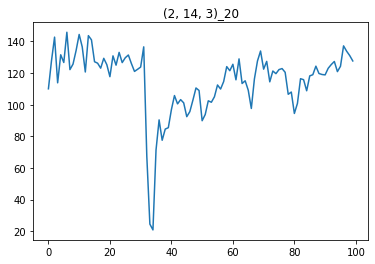

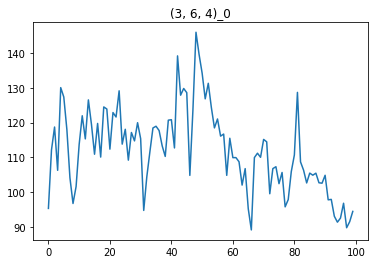

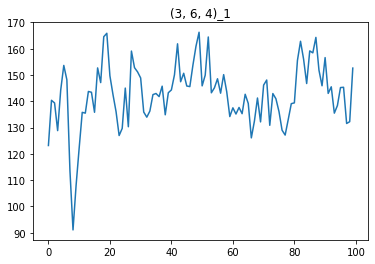

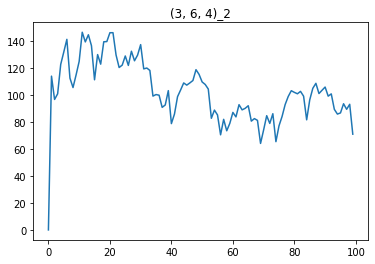

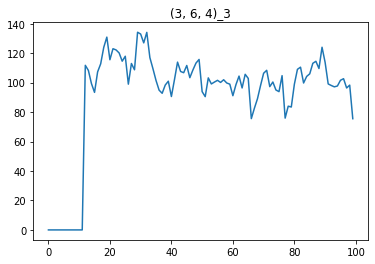

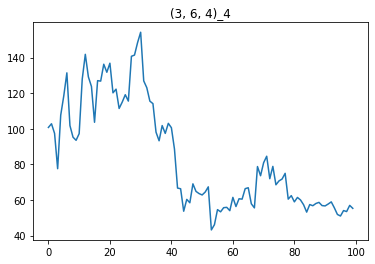

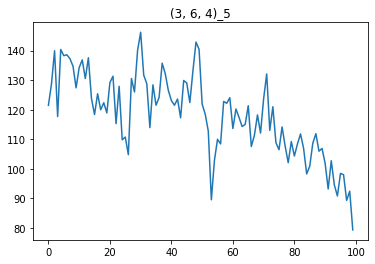

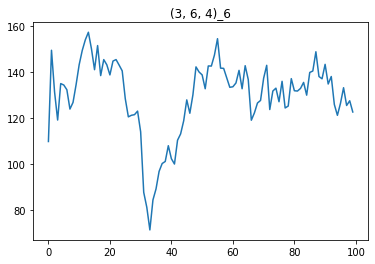

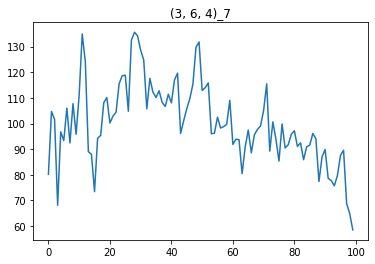

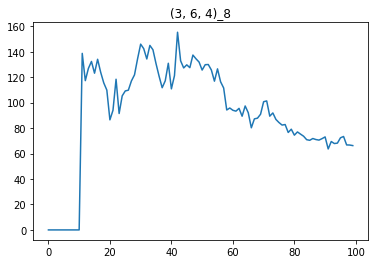

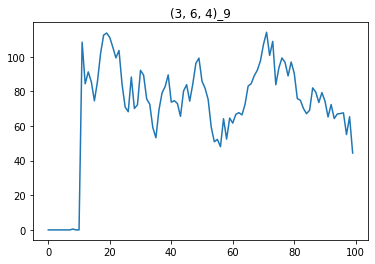

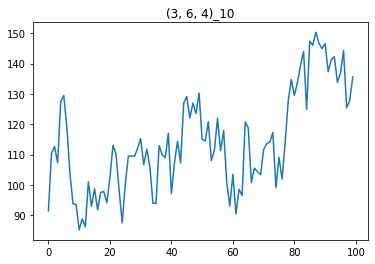

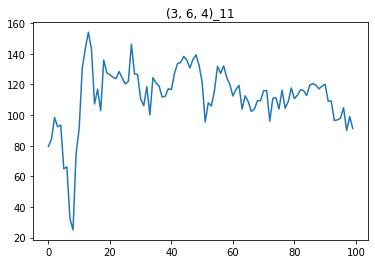

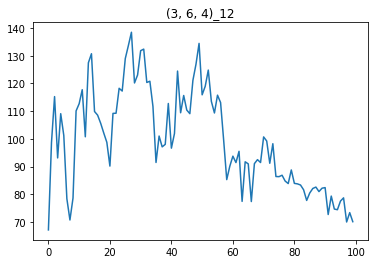

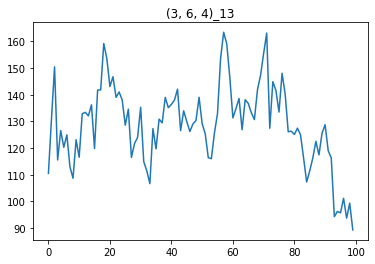

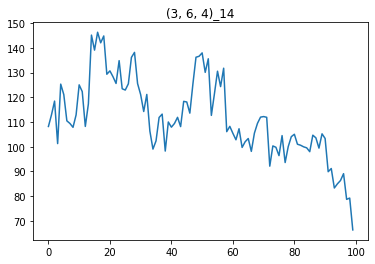

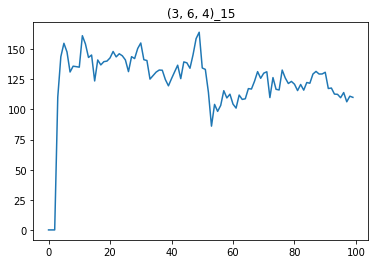

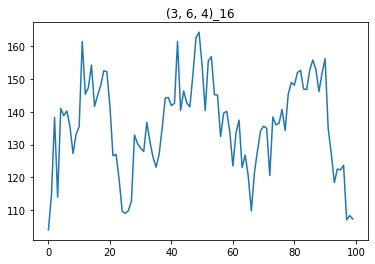

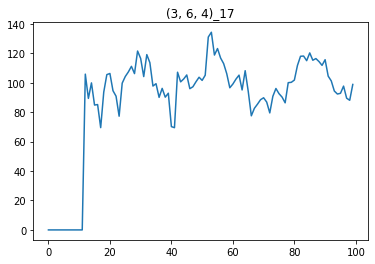

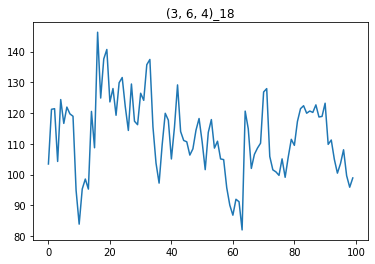

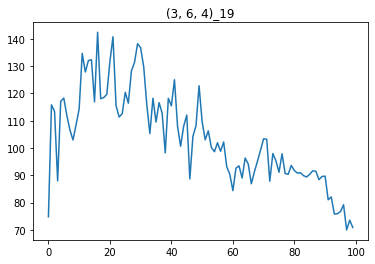

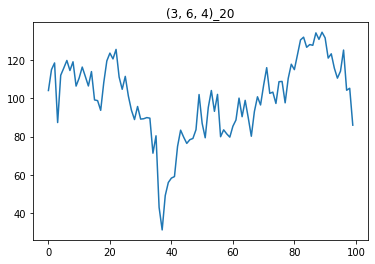

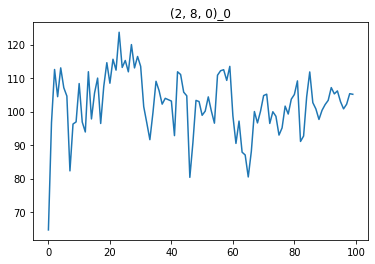

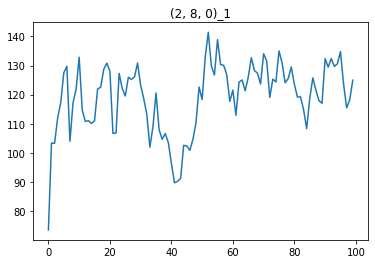

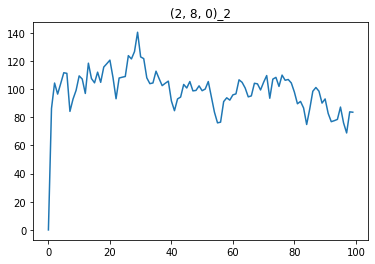

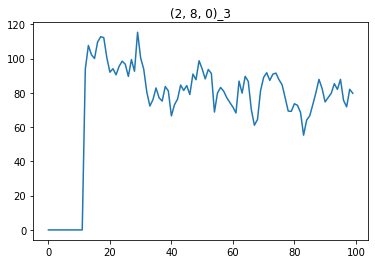

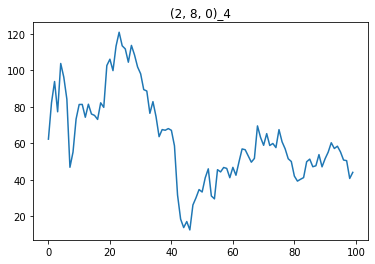

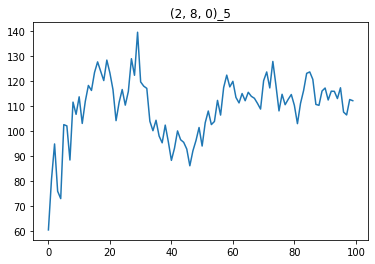

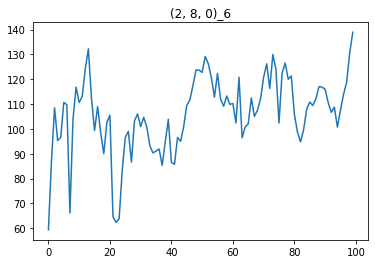

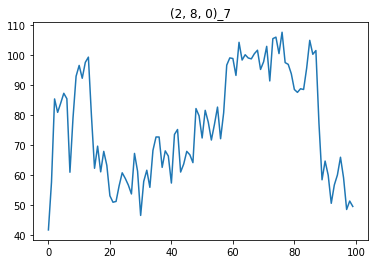

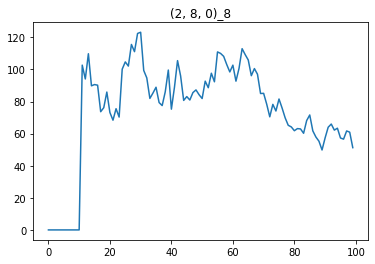

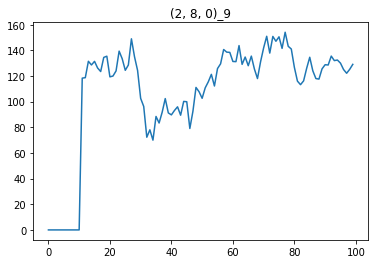

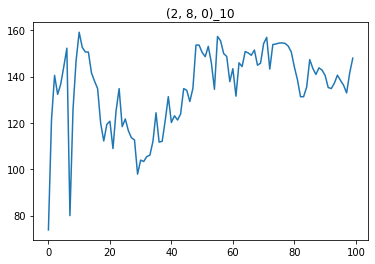

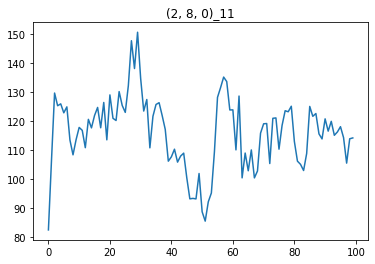

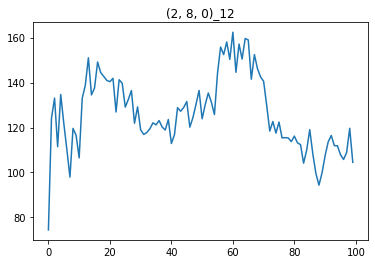

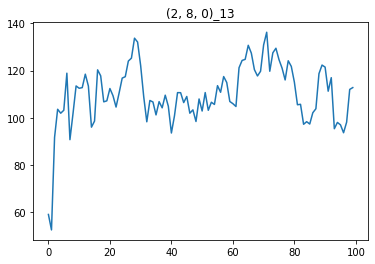

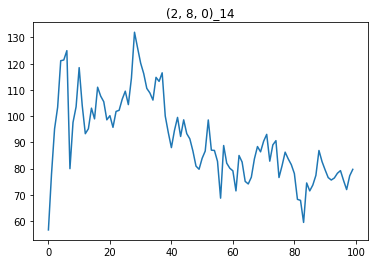

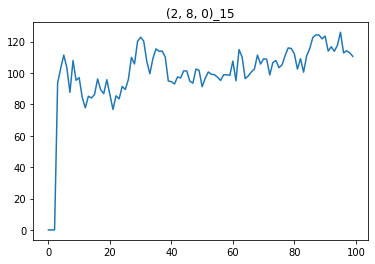

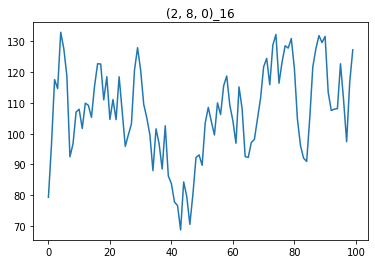

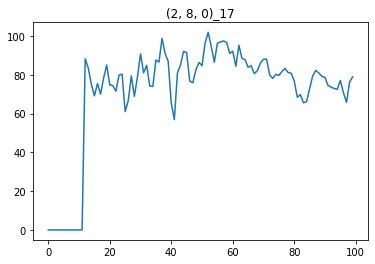

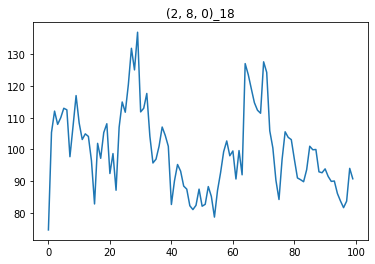

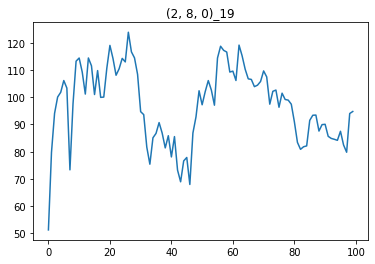

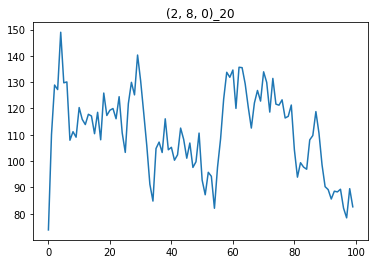

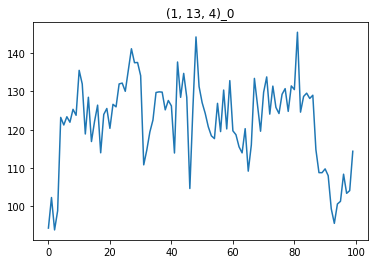

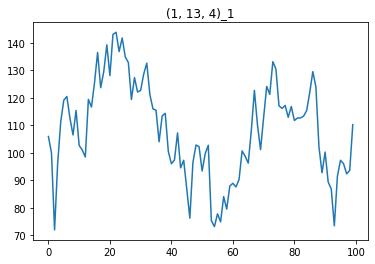

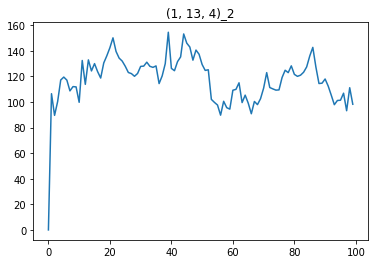

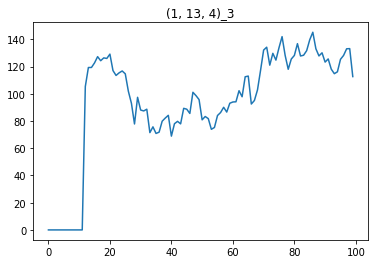

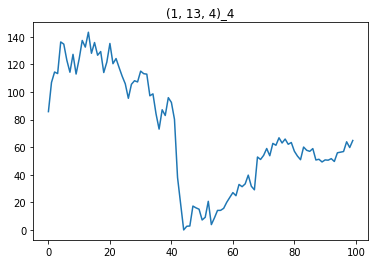

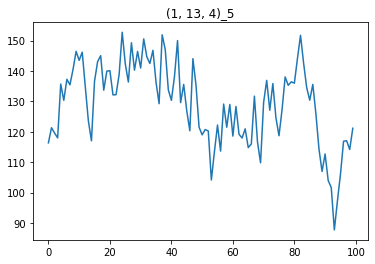

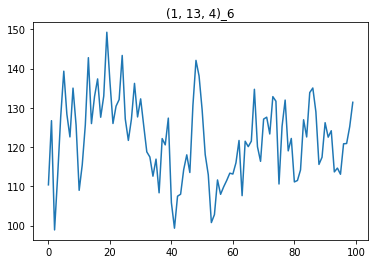

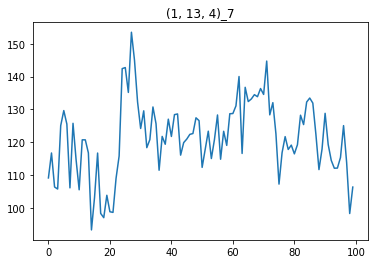

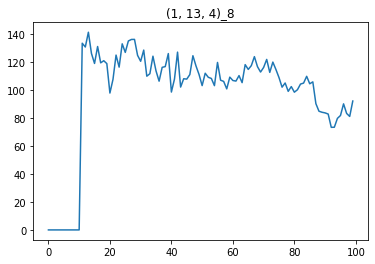

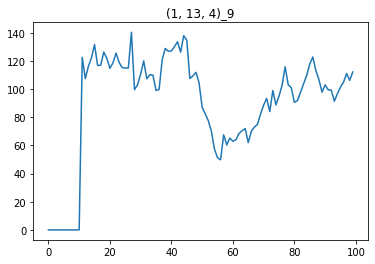

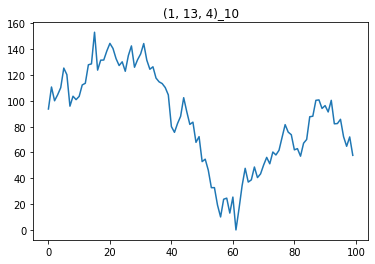

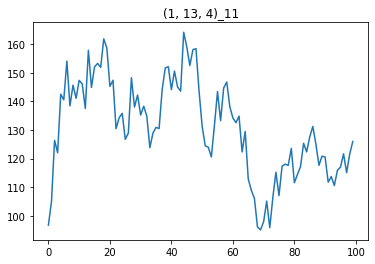

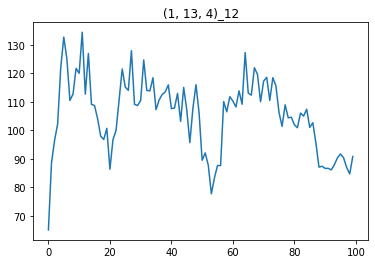

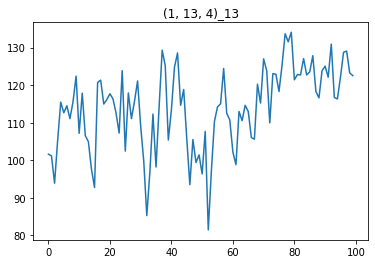

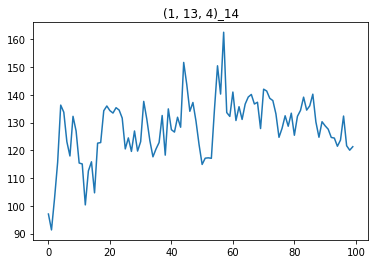

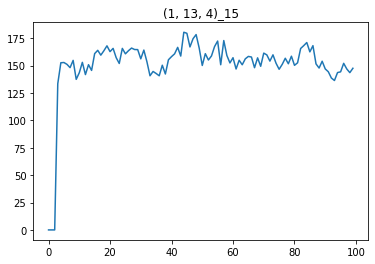

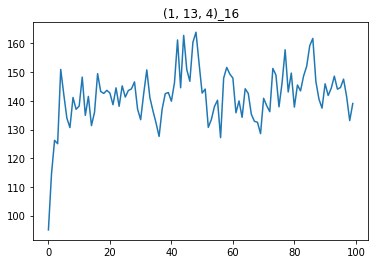

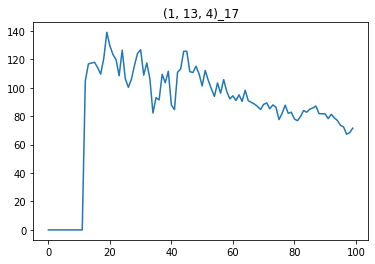

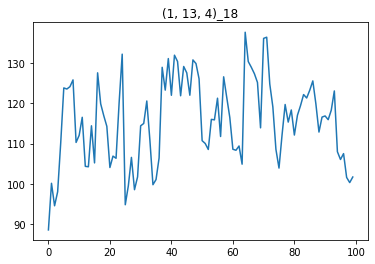

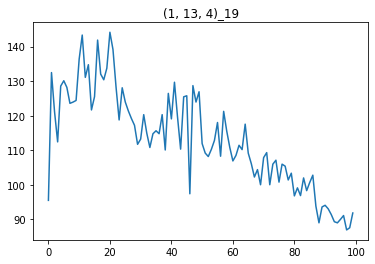

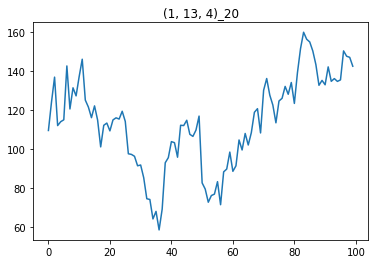

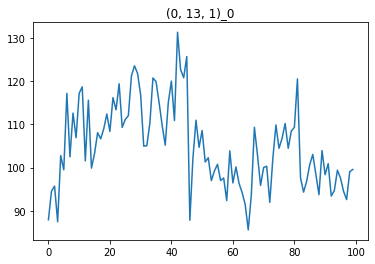

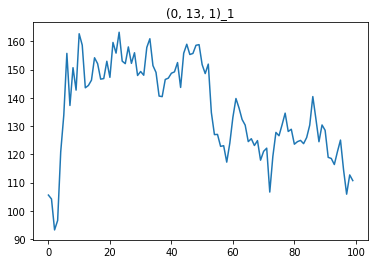

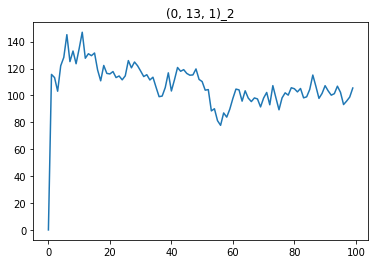

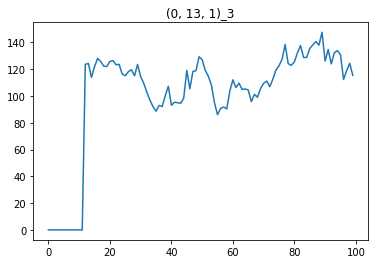

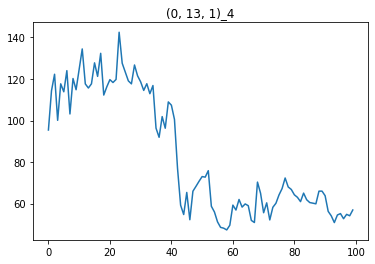

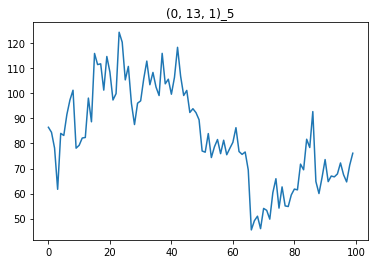

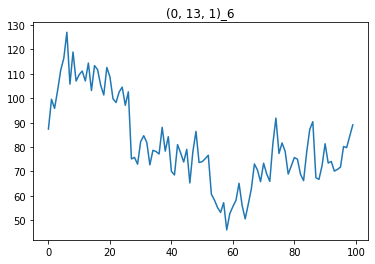

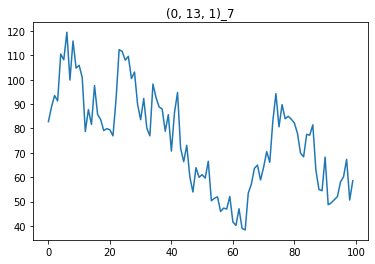

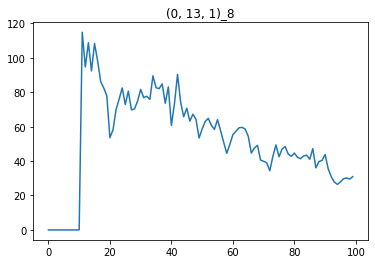

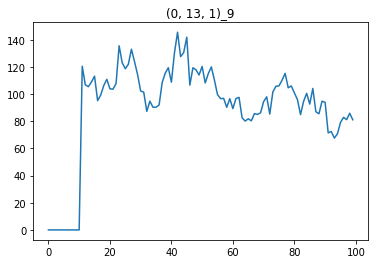

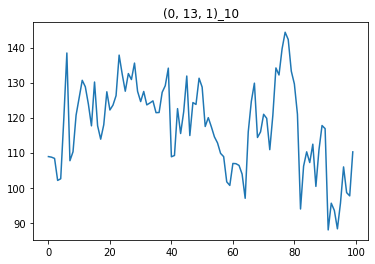

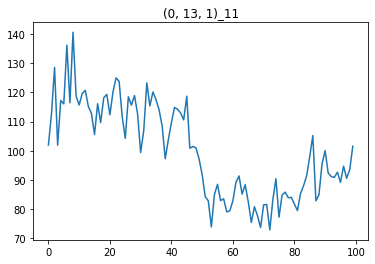

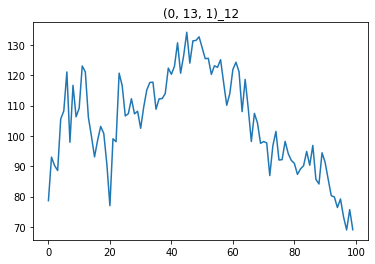

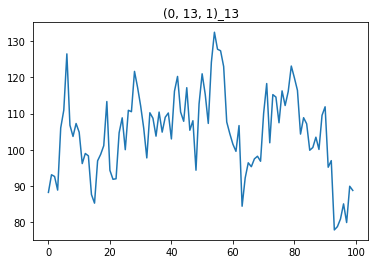

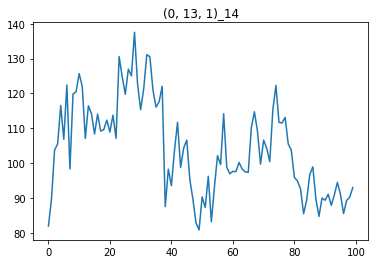

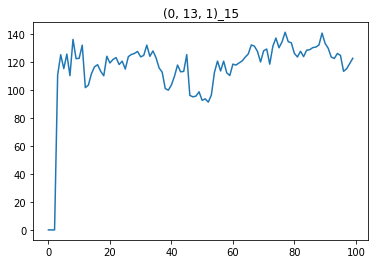

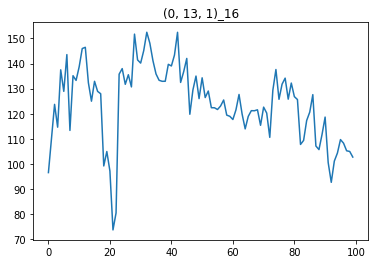

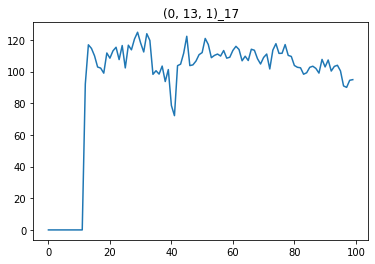

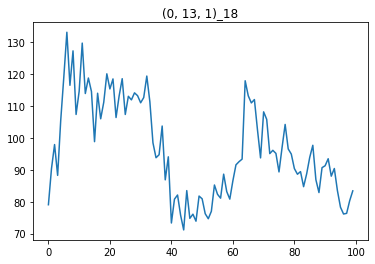

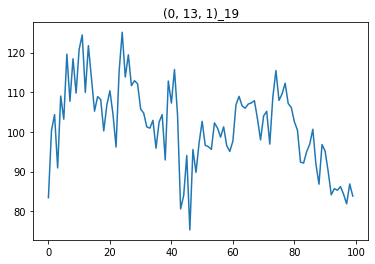

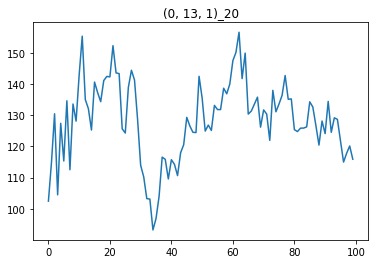

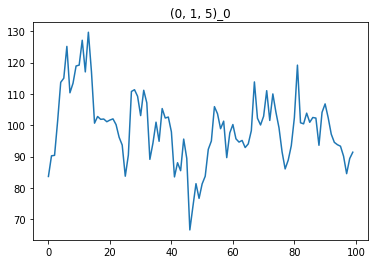

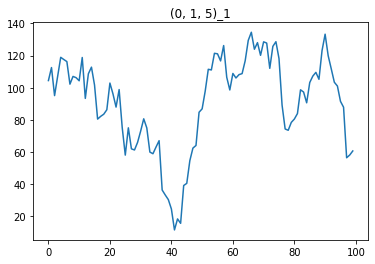

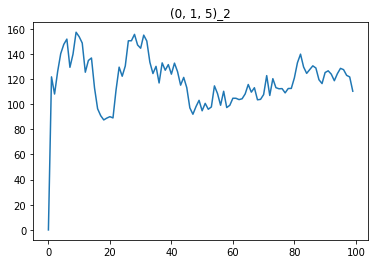

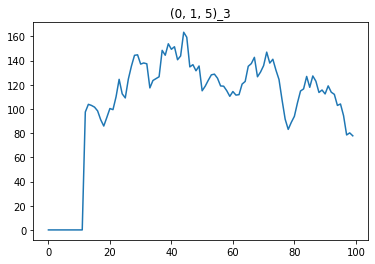

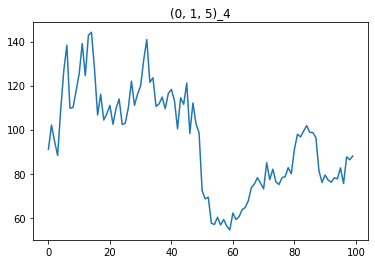

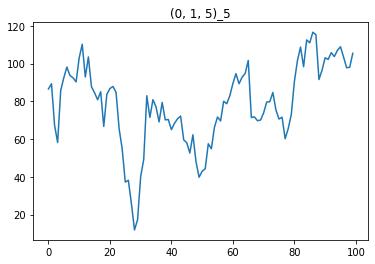

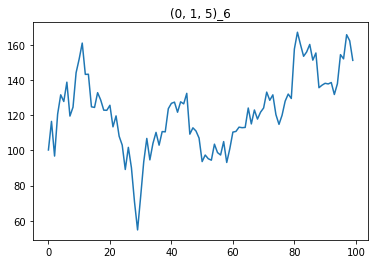

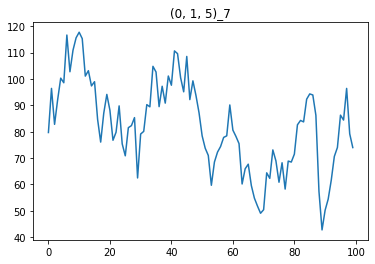

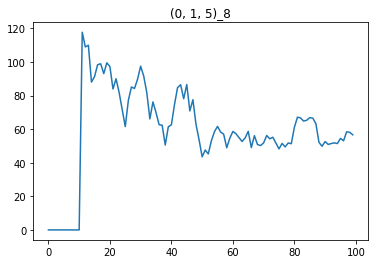

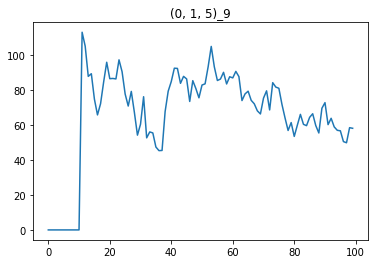

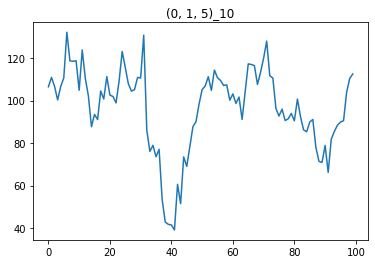

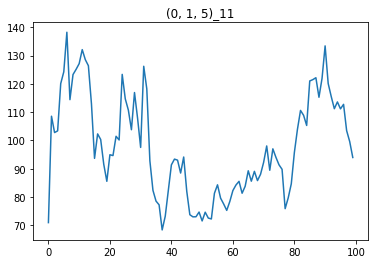

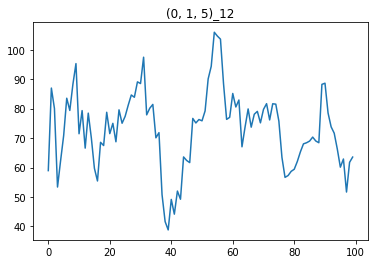

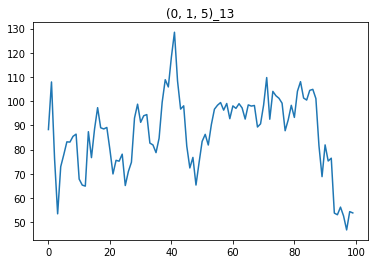

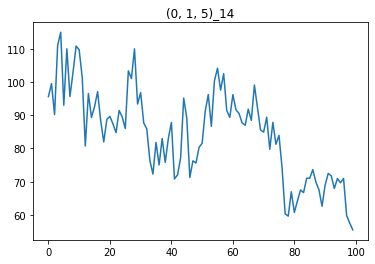

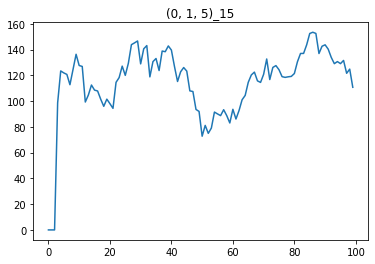

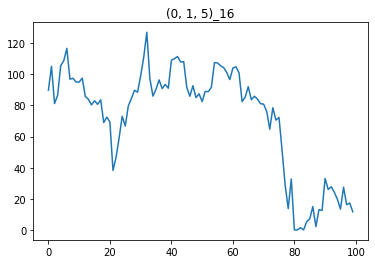

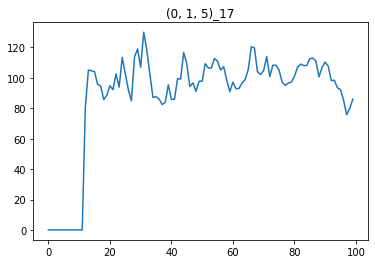

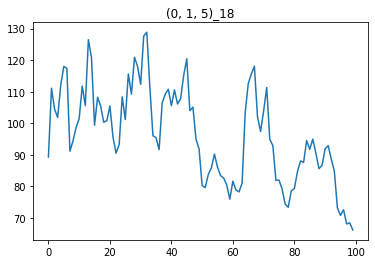

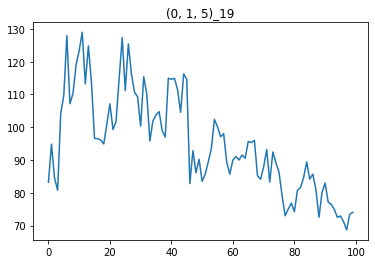

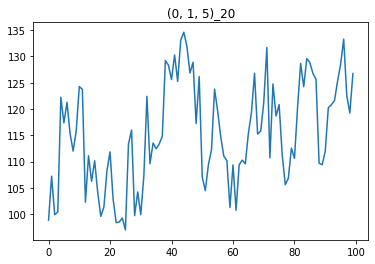

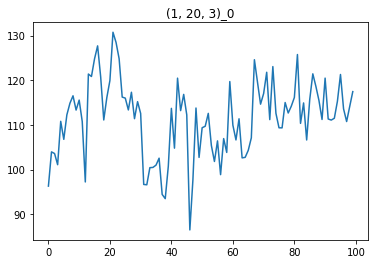

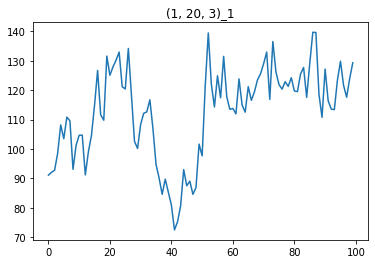

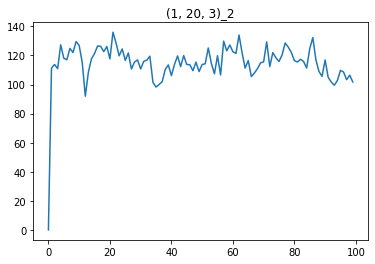

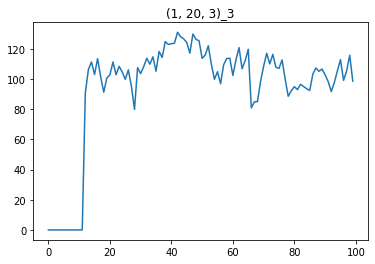

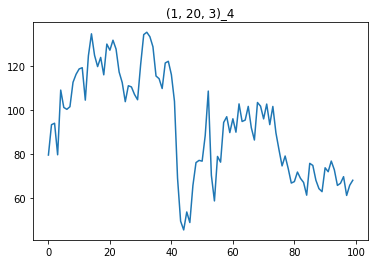

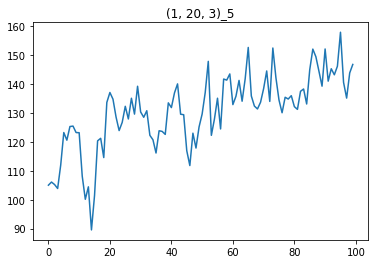

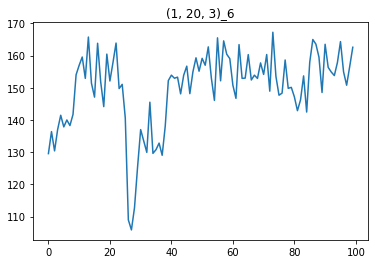

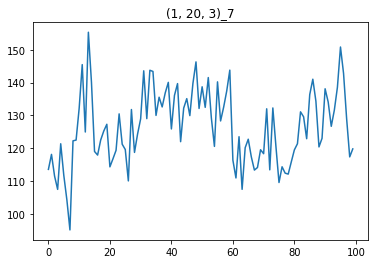

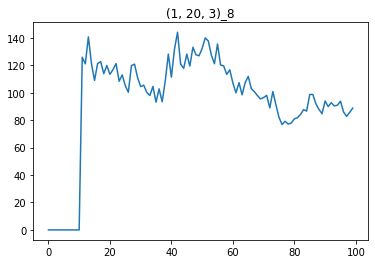

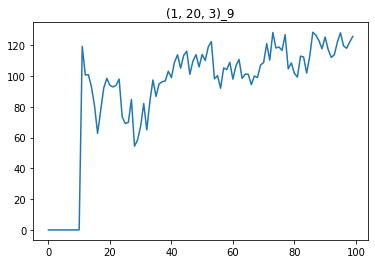

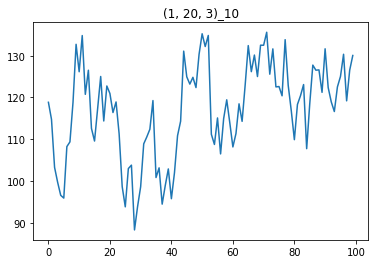

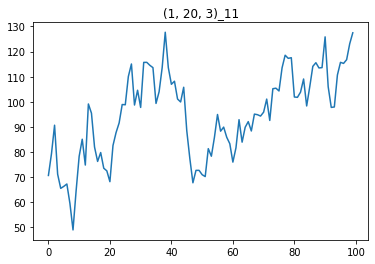

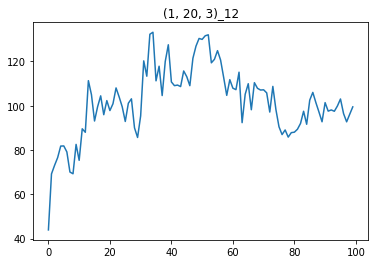

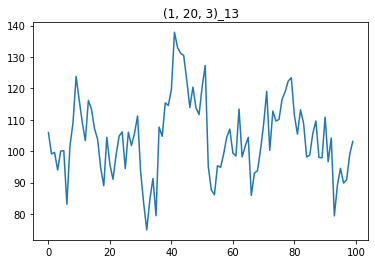

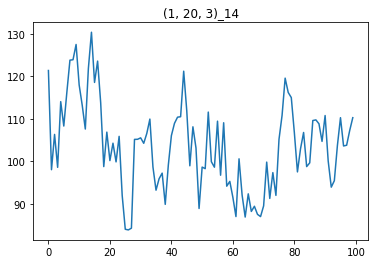

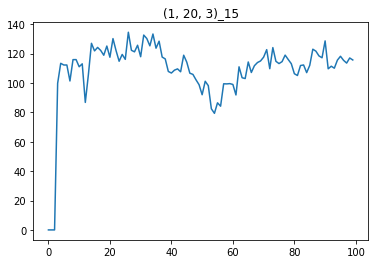

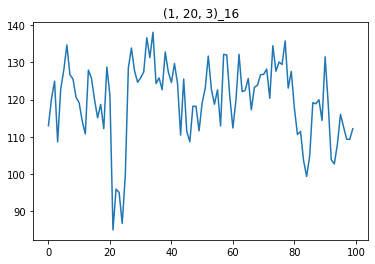

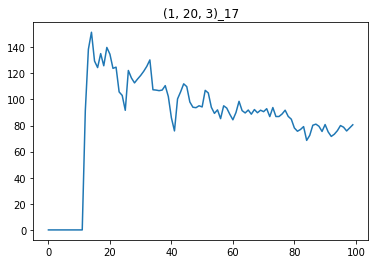

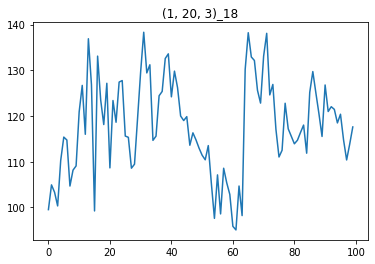

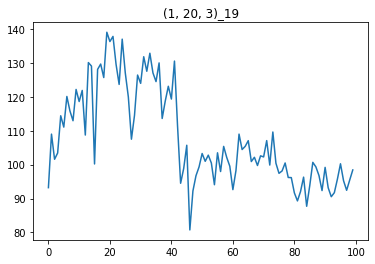

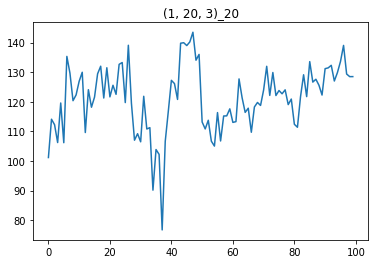

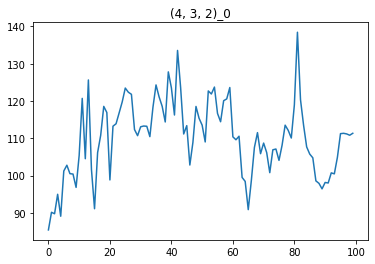

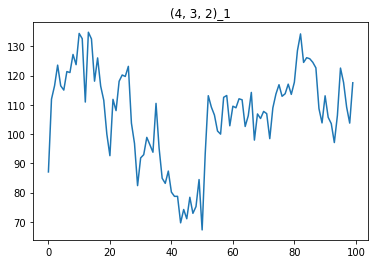

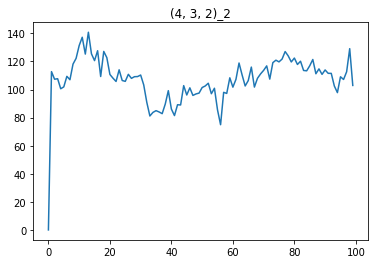

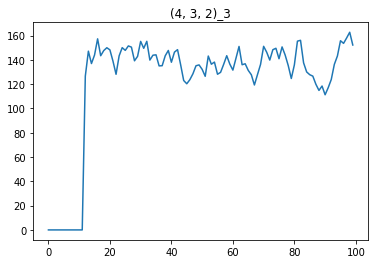

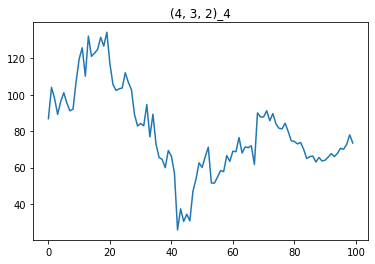

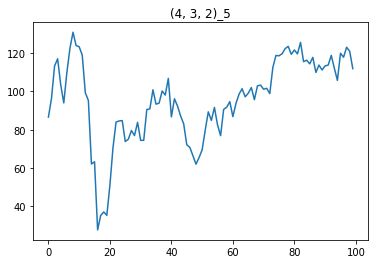

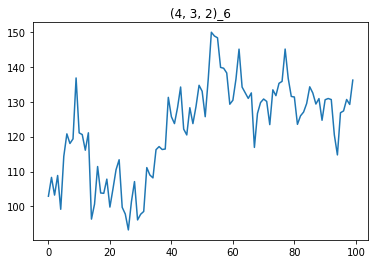

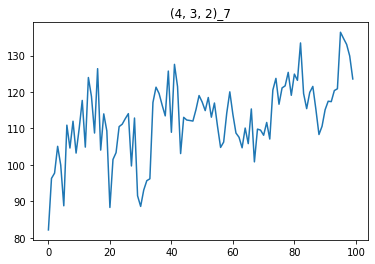

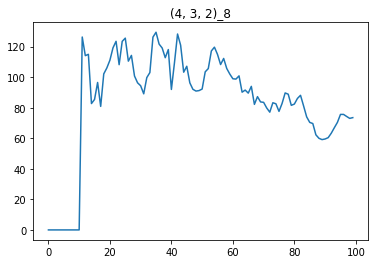

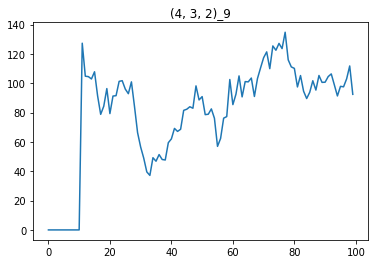

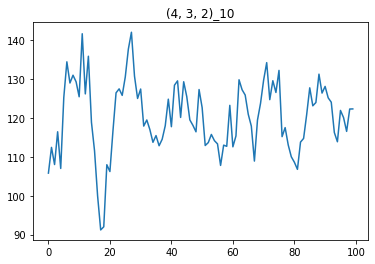

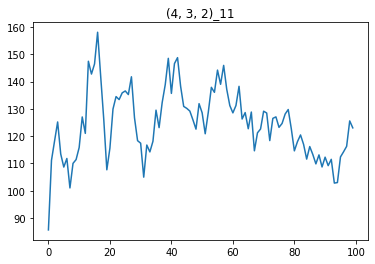

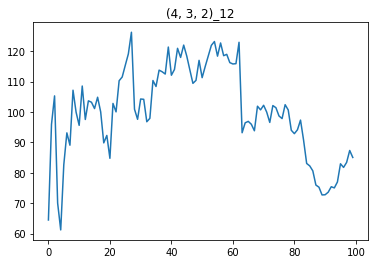

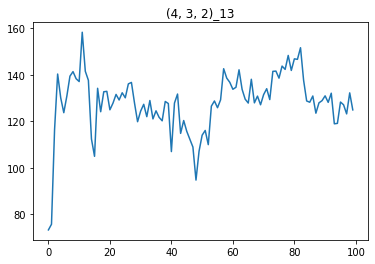

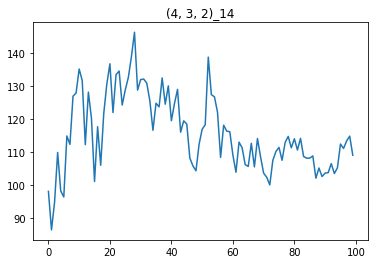

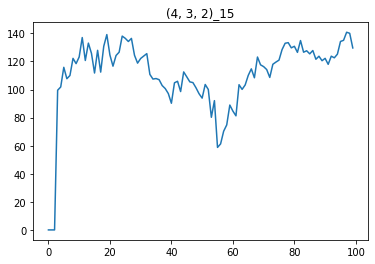

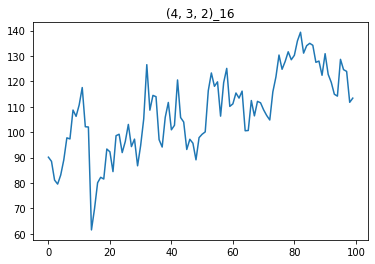

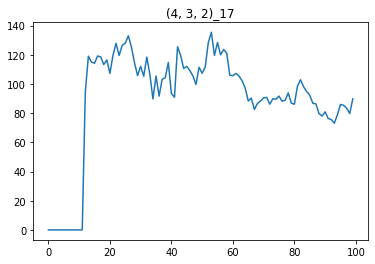

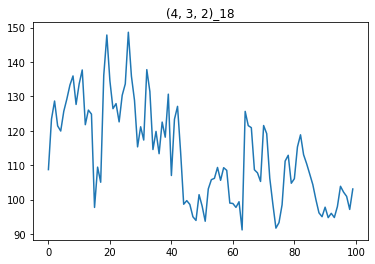

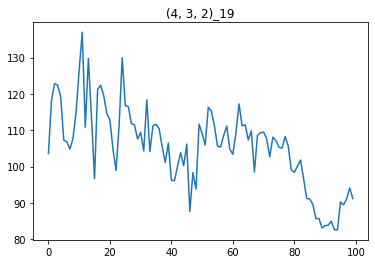

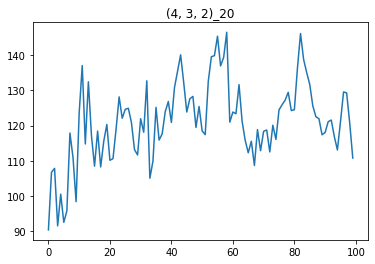

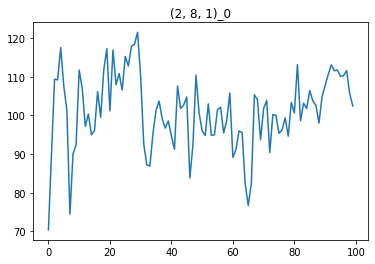

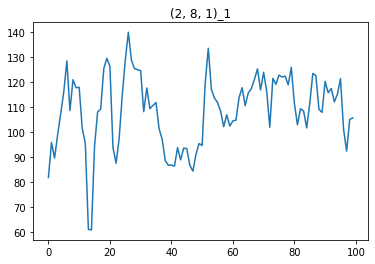

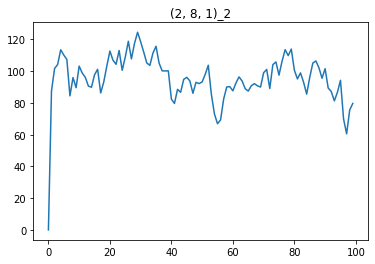

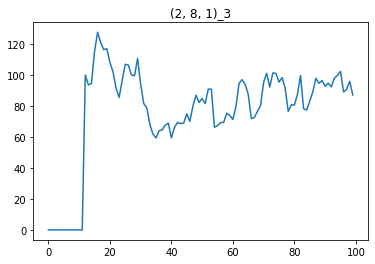

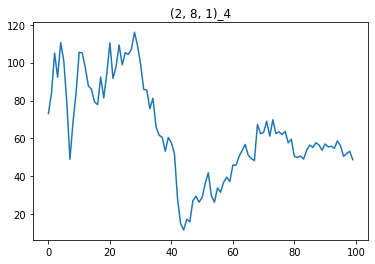

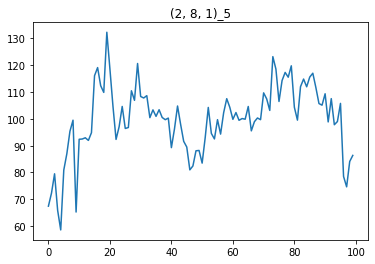

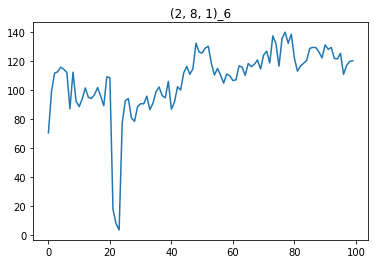

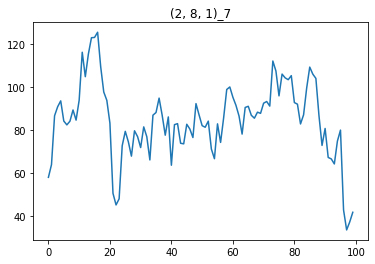

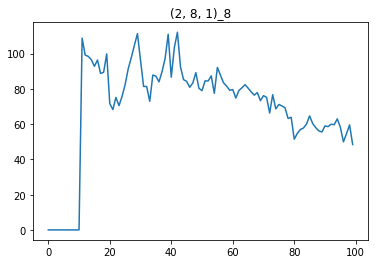

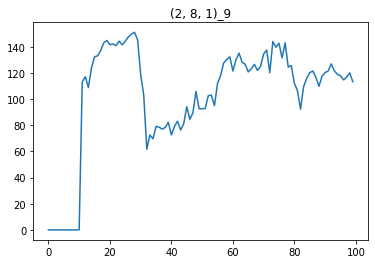

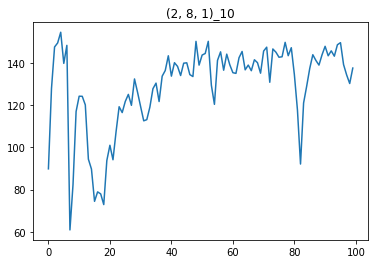

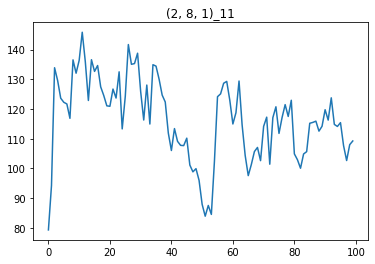

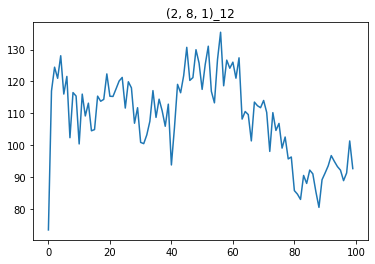

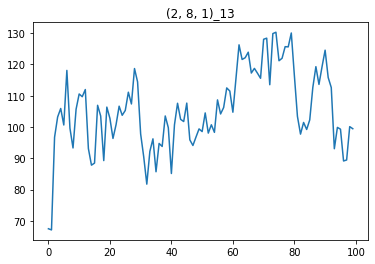

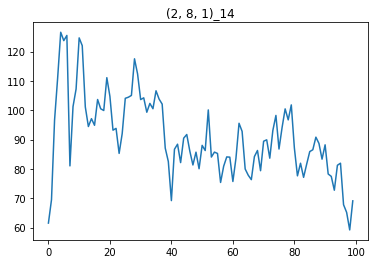

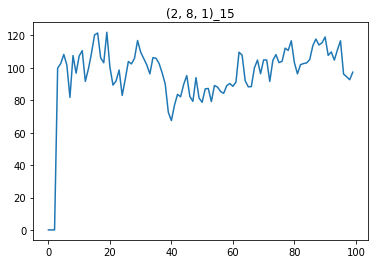

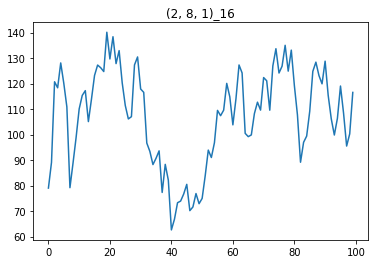

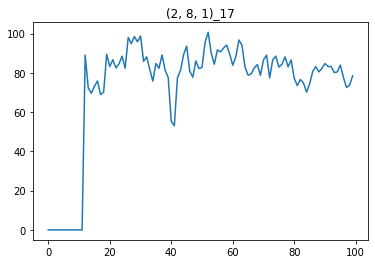

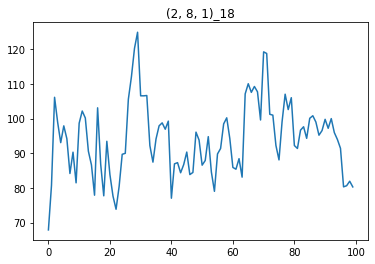

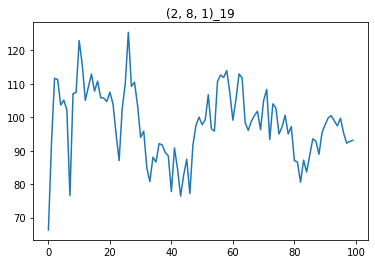

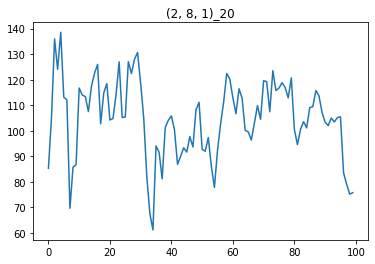

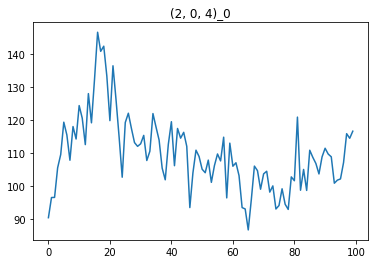

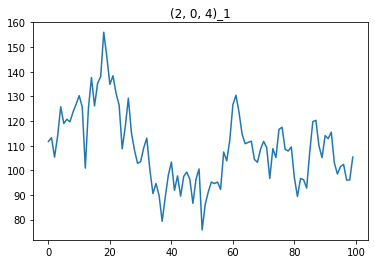

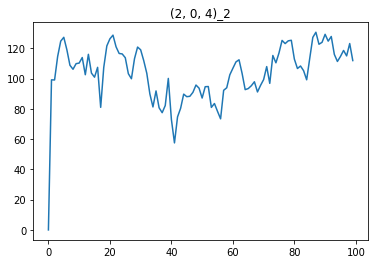

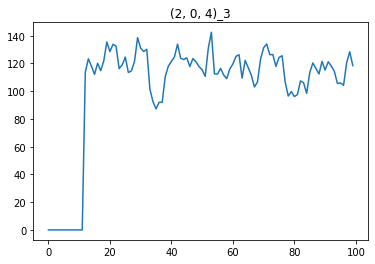

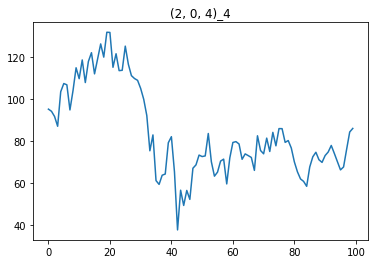

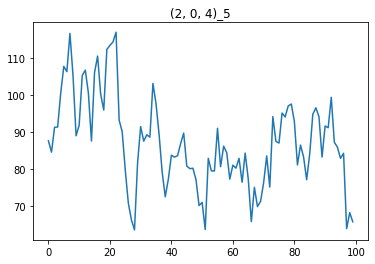

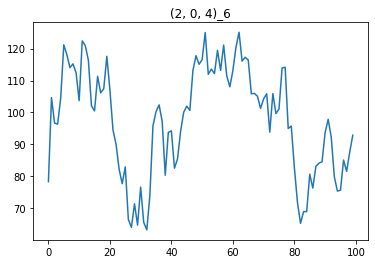

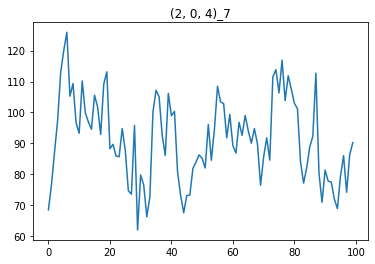

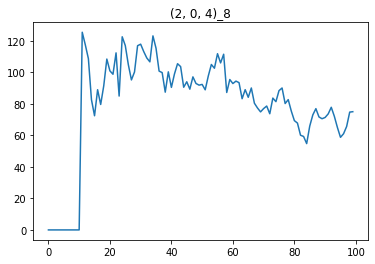

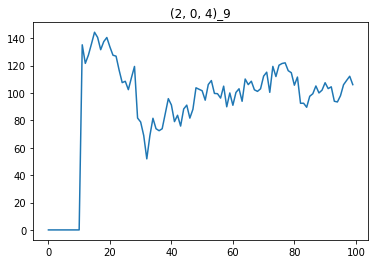

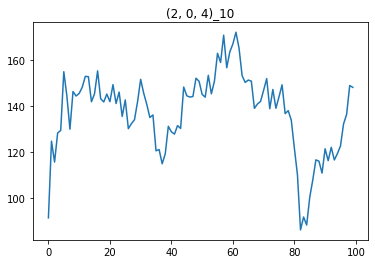

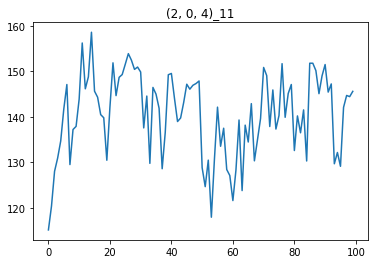

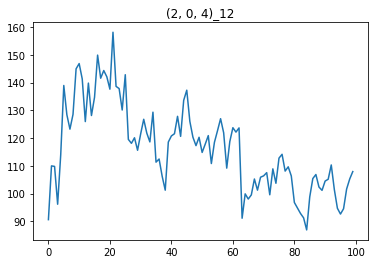

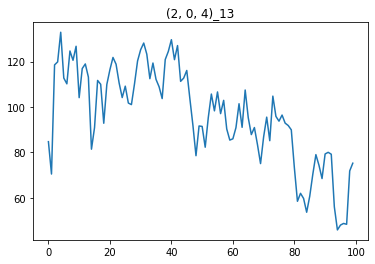

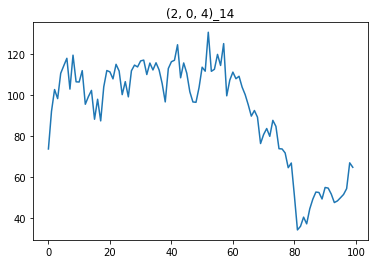

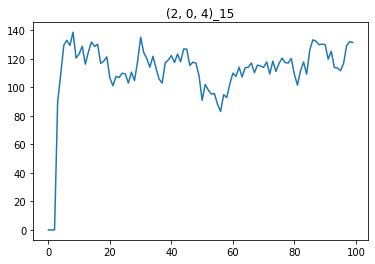

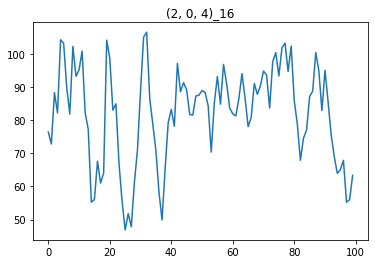

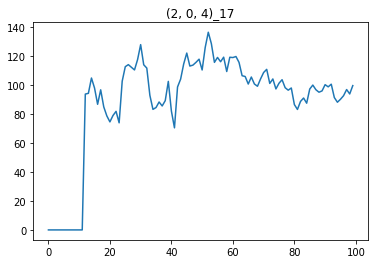

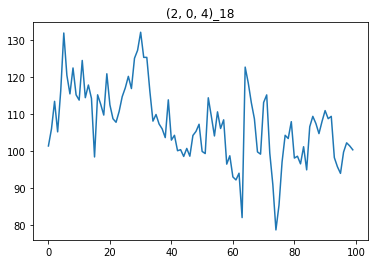

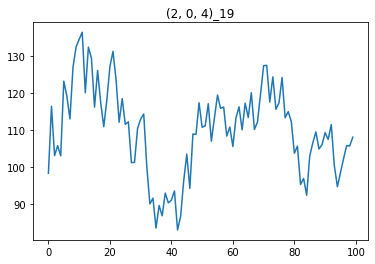

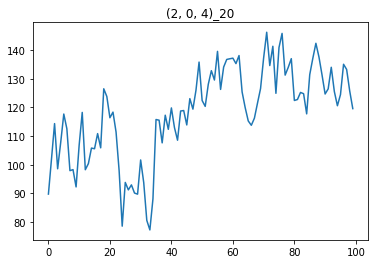

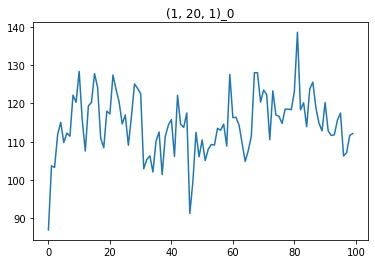

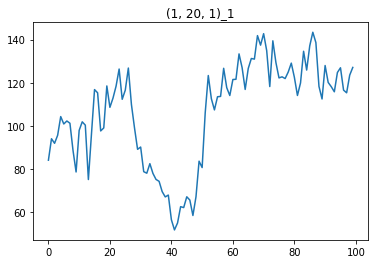

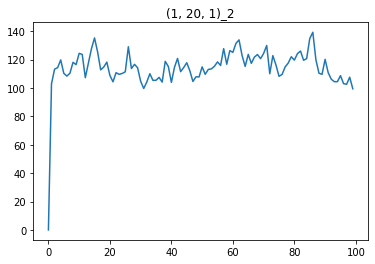

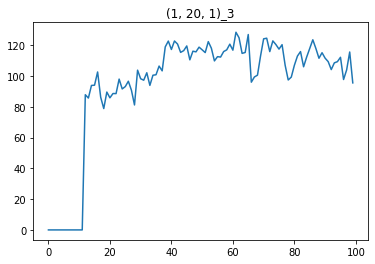

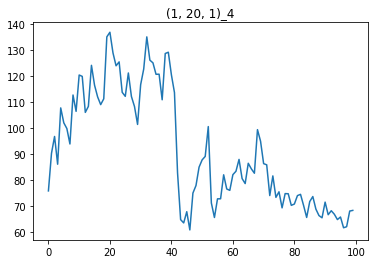

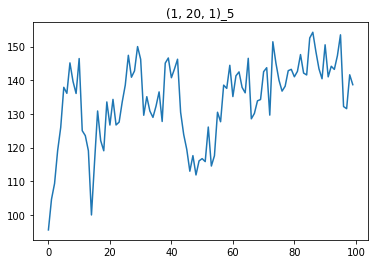

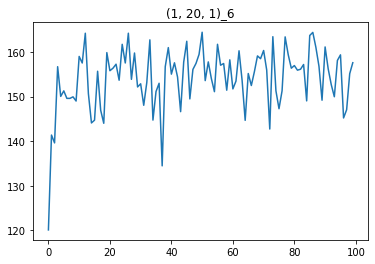

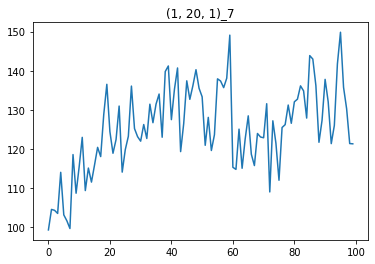

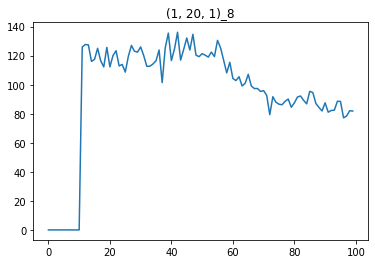

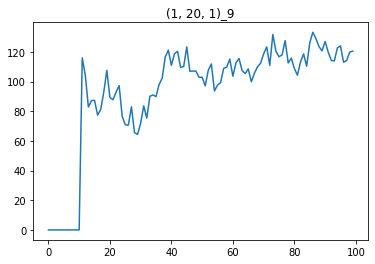

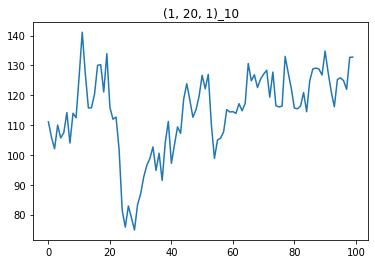

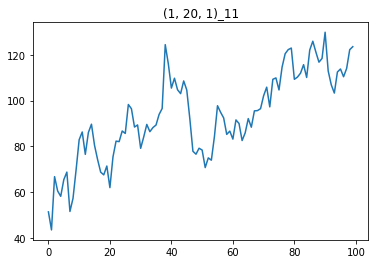

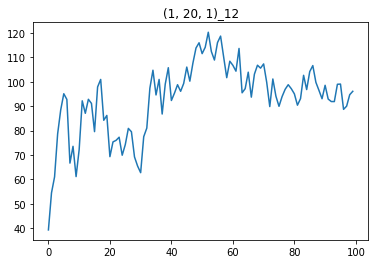

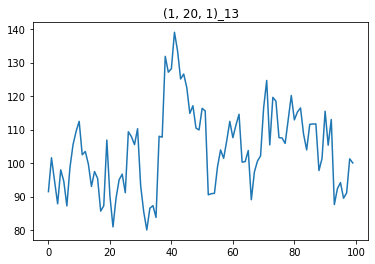

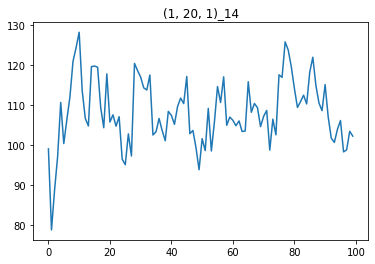

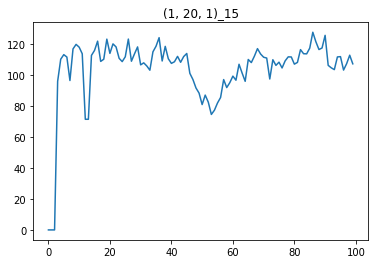

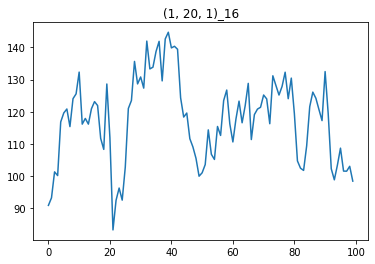

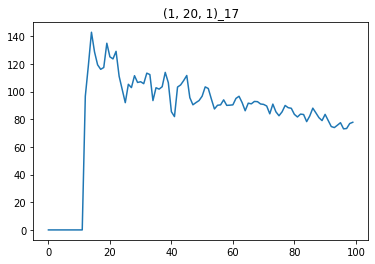

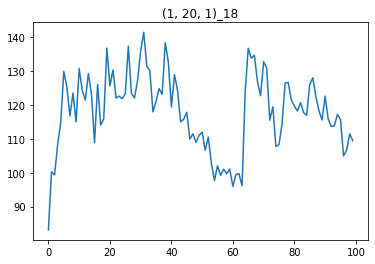

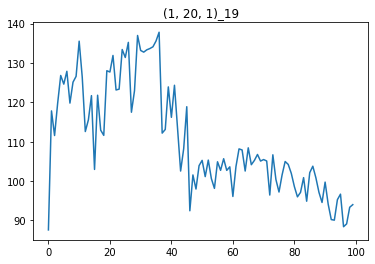

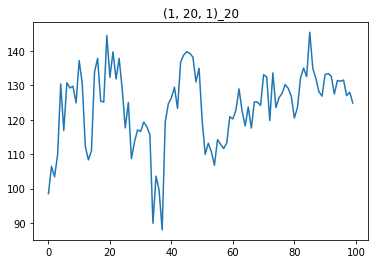

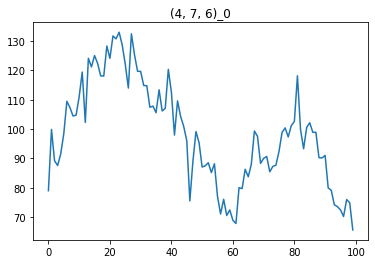

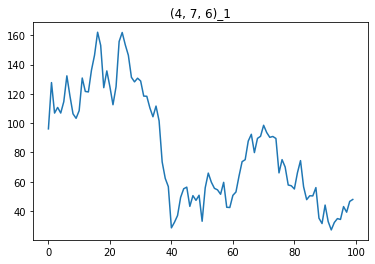

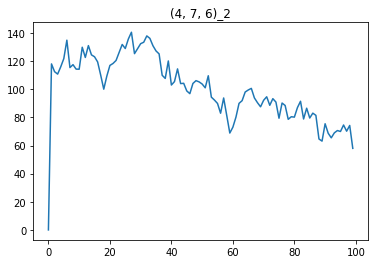

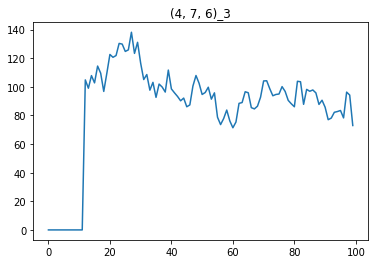

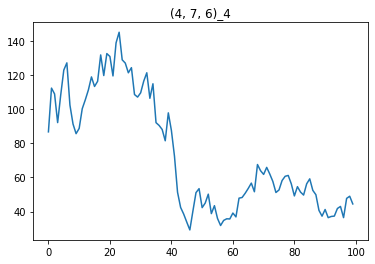

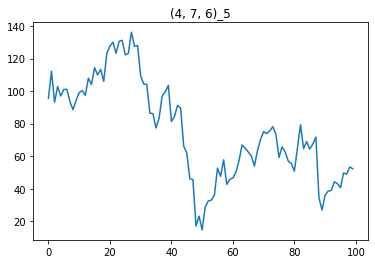

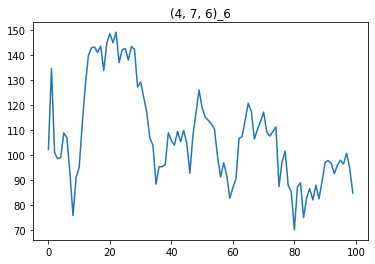

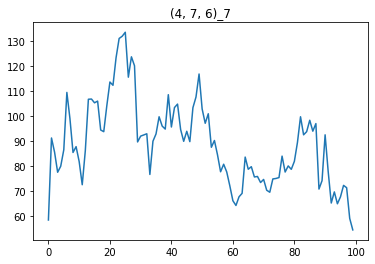

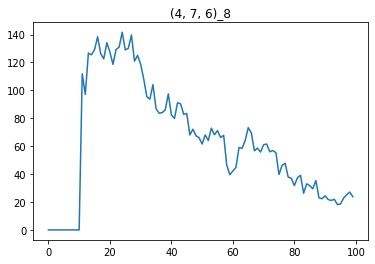

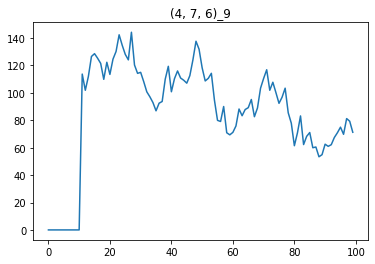

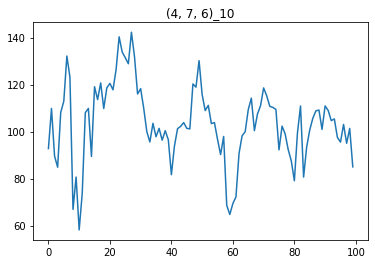

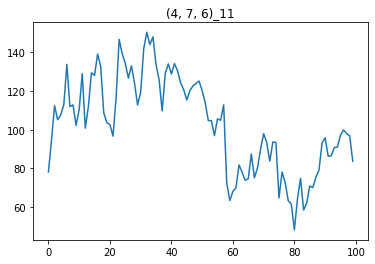

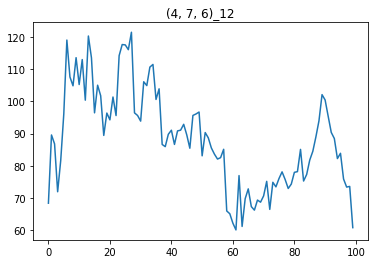

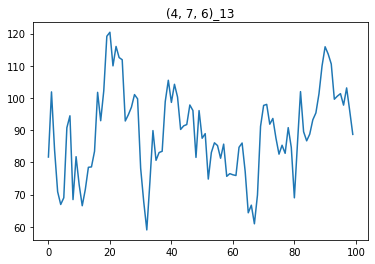

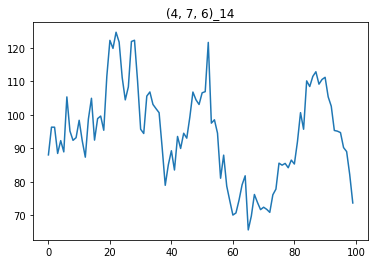

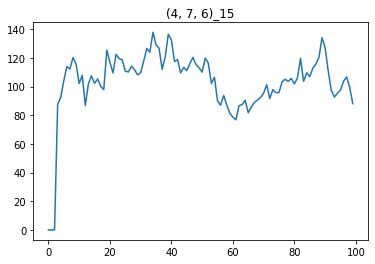

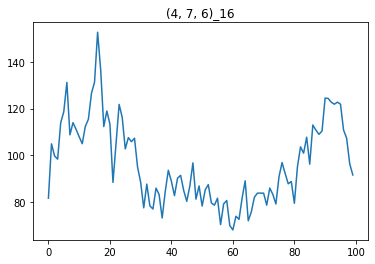

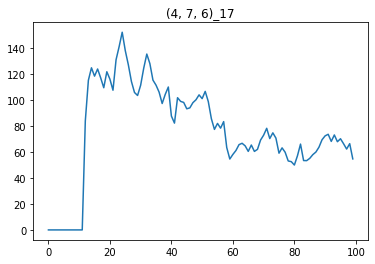

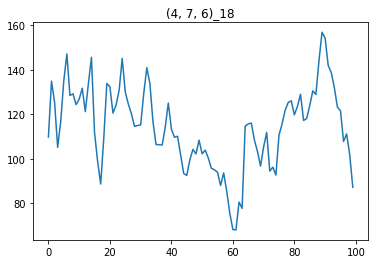

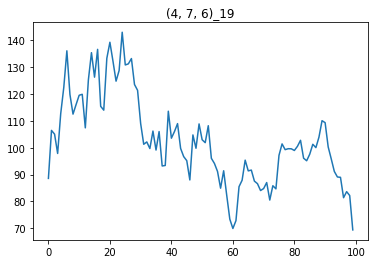

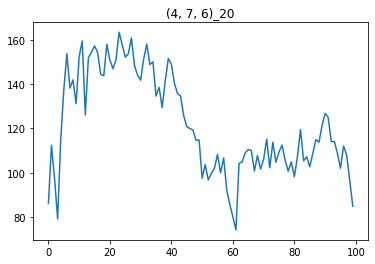

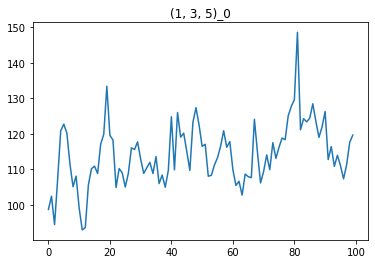

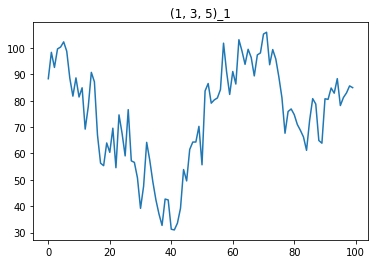

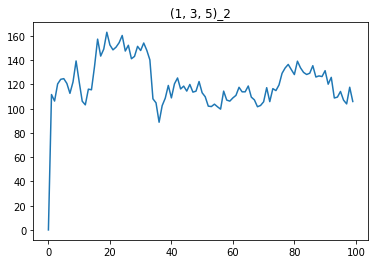

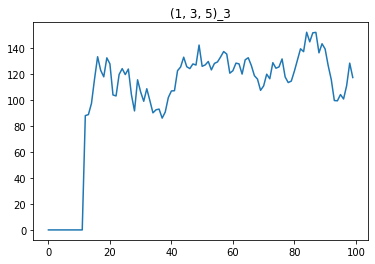

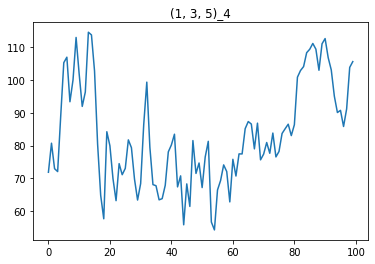

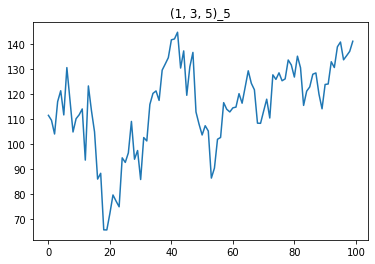

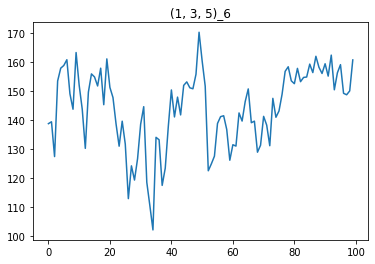

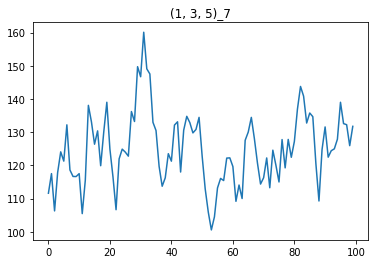

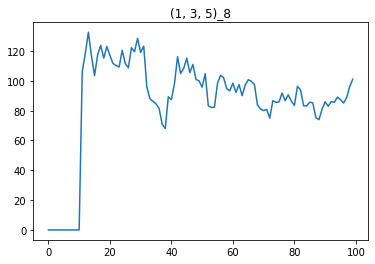

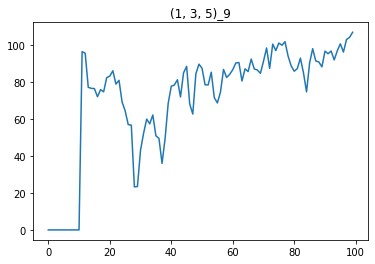

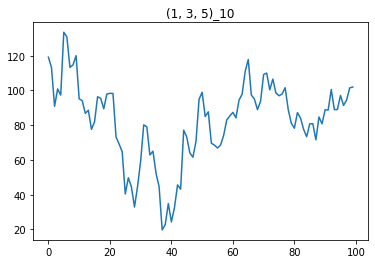

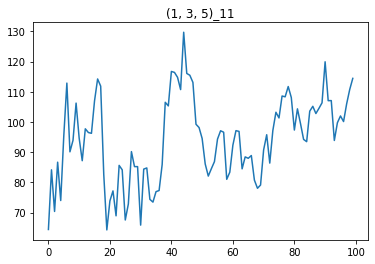

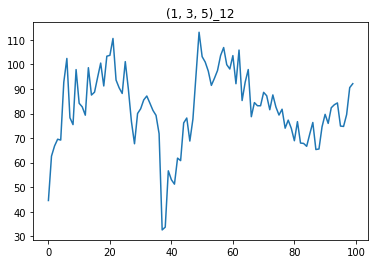

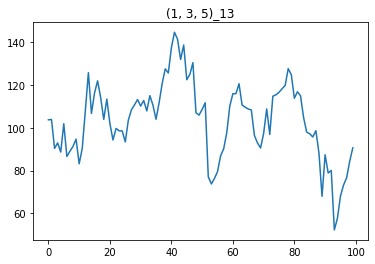

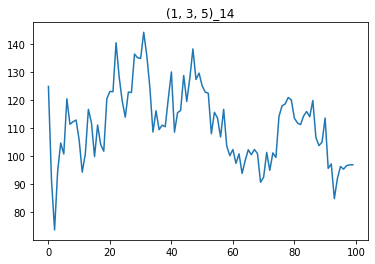

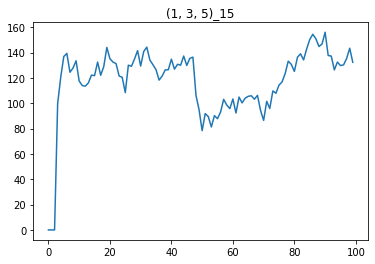

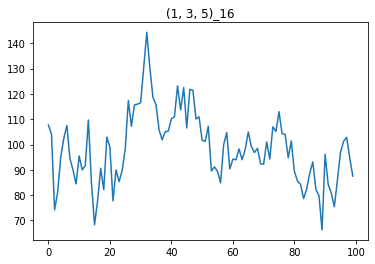

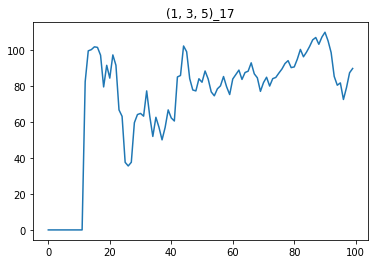

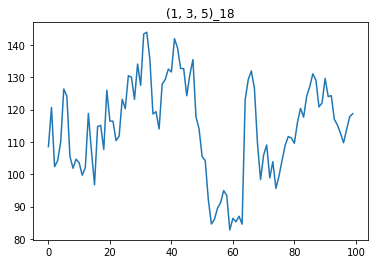

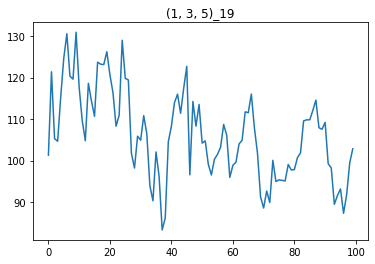

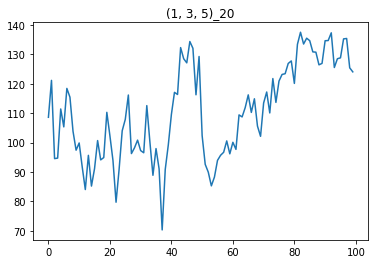

In [13]:
# lets plot all these states that we are tracking
States_track_file = open("States_tracked.pkl",'rb')
States_track_from_file = pickle.load(States_track_file)

for state in States_track_from_file:
    for a in States_track_from_file[state]:
        show_plot(States_track_from_file[state][a], '_'.join([str(state),str(a)]))

## State Q-values tracker:

- Seem to all show an intial rise and after a few iterations, the values are ossillating around certain range
- Perhaps a little more training can get them even more stable
- These Q-values are able to offer generally a good rewards around 2800 per episode on an average


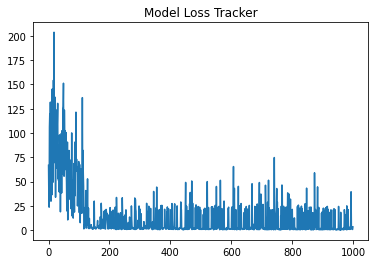

In [14]:
Model_loss_tracked = open("Model_loss_tracked.pkl",'rb')
Model_loss_tracked_from_file = pickle.load(Model_loss_tracked)

show_plot(Model_loss_tracked_from_file, "Model Loss Tracker")

## Loss Tracker:

- Losses are clearing going down as the model moves from exploration to exploitation
- This is another way to say that our model is approaching its own Q-Values it was predicting i.e, the model is able to chase towards the optimal Q-values
- In other words the model is converging


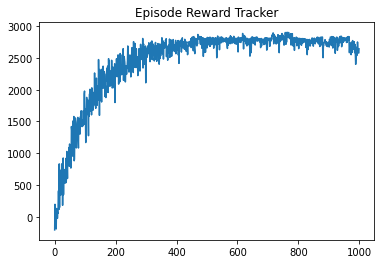

In [15]:
Rewards_tracked = open("Rewards_tracked.pkl",'rb')
Rewards_tracked_from_file = pickle.load(Rewards_tracked)

show_plot(Rewards_tracked_from_file, "Episode Reward Tracker")

## Rewards tracker:

- Rewards seem to peak at around 2800
- The graph peak looks exponentially rising and settling at peak
- The graph also contains the variation of rewards between 2400 - 2800 indicating assured rewards as govered by the DQN policy
- The lower bound of rewards seem to also increases as the the model training advances


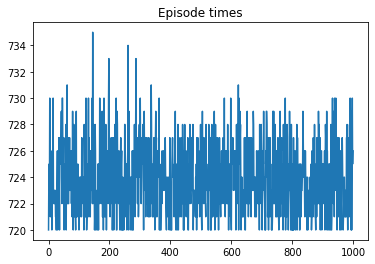

In [16]:
Episode_time_tracked_file = open("Episode_time_tracked.pkl",'rb')
Episode_time_tracked_from_file = pickle.load(Episode_time_tracked_file)

show_plot(Episode_time_tracked_from_file, "Episode times")

## Trip time tracker:

- Trip times sometimes exceed the 720 hour limit
- However, they seem to not overshoot much.
- Much of episodes had rides between 720 and 726 seeing the denseness of the graph which means cab drivers are serving their last trip and going for battery recharge of their vehicle


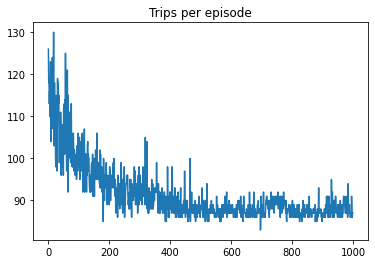

In [17]:
Trips_per_episode_tracker_file = open("Trips_per_episode_tracked.pkl",'rb')
Trips_per_episode_tracker_from_file = pickle.load(Trips_per_episode_tracker_file)

show_plot(Trips_per_episode_tracker_from_file, "Trips per episode")

## Trips per episode

- Initially when the training started more number of trips were taken
- Gradually the value of trips done per episode settles downs at around 88 to 90


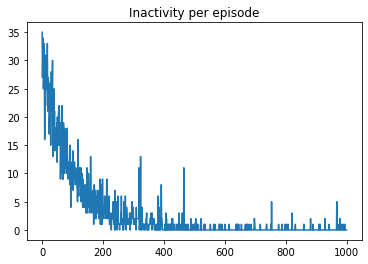

In [20]:
Inactivity_per_episode_tracker_file = open("Inactivity_per_episode_tracked.pkl",'rb')
Inactivity_per_episode_tracker_from_file = pickle.load(Inactivity_per_episode_tracker_file)

show_plot(Inactivity_per_episode_tracker_from_file, "Inactivity per episode")

## Inactivity time tracker

- The instances where the Cab agent takes no action (0,0) was high
- As the training progresses, cab agent minimizes the number of inactivity periods
- This indicates that the DQN is chasing rewards and good rewards arrive only if trips are made optimally


#### Epsilon-decay sample function used to design the exploration vs exploitation curve and the gradual descent


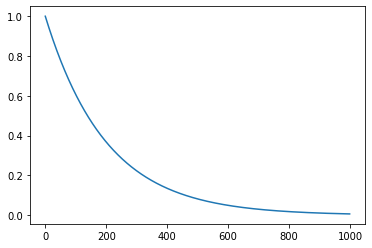

In [21]:
import numpy as np

# for plotting graphs
import matplotlib.pyplot as plt

EPISODES = 1000
time = np.arange(0,EPISODES)
epsilon = []
for i in range(0,EPISODES):
    epsilon.append(0 + (1 - 0) * np.exp(-0.005*i))

plt.plot(time, epsilon)
plt.show()

## The function for decay chosen as given below. Reasons being

- Simplicity of the formula
- Ideal decrease from exploiting vs exploration


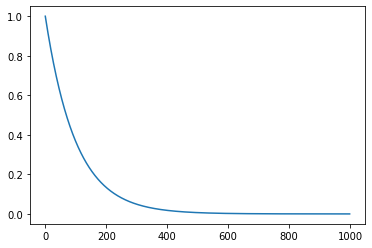

In [22]:
# for plotting graphs
import matplotlib.pyplot as plt

EPISODES = 1000
time = np.arange(0,EPISODES)
epsilon_array = []
epsilon_max = 1
epsilon_min = 0
epsilon = epsilon_max
epsilon_decay = 0.99
for i in range(0,EPISODES):
    epsilon_array.append(epsilon)
    if epsilon > epsilon_min:
      epsilon = epsilon*epsilon_decay

plt.plot(time, epsilon_array)
plt.show()